# Constructing empirical PSFs of HST and JWST

In this tutorial, we will construct empirical PSFs of HST and JWST imaging using [Photutils](https://photutils.readthedocs.io/en/stable/). A more comprehensive tutorial and explanations can be seen at the [Photutil's website](https://photutils.readthedocs.io/en/stable/epsf.html).

In [1]:
import os
import sys
import numpy as np
from astropy.io import fits
import matplotlib.pyplot as plt
from astropy.visualization import simple_norm
from photutils.detection import find_peaks
from astropy.table import Table
from astropy.nddata import NDData
from photutils.psf import extract_stars
from photutils.psf import EPSFBuilder

#%matplotlib inline


## List the input images

In [2]:
filters = ['jwst_nircam_f090w', 'jwst_nircam_f115w', 'jwst_nircam_f150w', 'jwst_nircam_f200w', 'jwst_nircam_f277w', 'jwst_nircam_f356w', 'jwst_nircam_f410m', 'jwst_nircam_f444w']

nbands = len(filters)
print ("Number of filters: %d" % nbands)

fil_names = ['JWST_F090W', 'JWST_F115W', 'JWST_F150W', 'JWST_F200W', 'JWST_F277W', 'JWST_F356W', 'JWST_F410M', 'JWST_F444W']


# directory of the images
dir_images = '/Users/quocanh1306/Downloads/'

# Input science images
sci_img = {}
sci_img['jwst_nircam_f090w'] =  'primer-cosmos-east-grizli-v7.0-f090w-clear_drc_sci.fits.gz'
sci_img['jwst_nircam_f115w'] =  'primer-cosmos-east-grizli-v7.0-f115w-clear_drc_sci.fits.gz'
sci_img['jwst_nircam_f150w'] =  'primer-cosmos-east-grizli-v7.0-f150w-clear_drc_sci.fits.gz'
sci_img['jwst_nircam_f200w'] =  'primer-cosmos-east-grizli-v7.0-f200w-clear_drc_sci.fits.gz'
sci_img['jwst_nircam_f277w'] =  'primer-cosmos-east-grizli-v7.0-f277w-clear_drc_sci.fits.gz' 
sci_img['jwst_nircam_f356w'] =  'primer-cosmos-east-grizli-v7.0-f356w-clear_drc_sci.fits.gz'
sci_img['jwst_nircam_f410m'] =  'primer-cosmos-east-grizli-v7.0-f410m-clear_drc_sci.fits.gz'
sci_img['jwst_nircam_f444w'] =  'primer-cosmos-east-grizli-v7.0-f444w-clear_drc_sci.fits.gz'

# Input weight images
wht_img = {}
wht_img['jwst_nircam_f090w'] =  'primer-cosmos-east-grizli-v7.0-f090w-clear_drc_wht.fits.gz'
wht_img['jwst_nircam_f115w'] =  'primer-cosmos-east-grizli-v7.0-f115w-clear_drc_wht.fits.gz'
wht_img['jwst_nircam_f150w'] =  'primer-cosmos-east-grizli-v7.0-f150w-clear_drc_wht.fits.gz'
wht_img['jwst_nircam_f200w'] =  'primer-cosmos-east-grizli-v7.0-f200w-clear_drc_wht.fits.gz'
wht_img['jwst_nircam_f277w'] =  'primer-cosmos-east-grizli-v7.0-f277w-clear_drc_wht.fits.gz' 
wht_img['jwst_nircam_f356w'] =  'primer-cosmos-east-grizli-v7.0-f356w-clear_drc_wht.fits.gz'
wht_img['jwst_nircam_f410m'] =  'primer-cosmos-east-grizli-v7.0-f410m-clear_drc_wht.fits.gz'
wht_img['jwst_nircam_f444w'] =  'primer-cosmos-east-grizli-v7.0-f444w-clear_drc_wht.fits.gz'



Number of filters: 8


In [3]:
import os
os.environ["SPS_HOME"] = "/Users/quocanh1306/Desktop/Research/highredshiftgalaxies/fsps"
os.environ["PIXEDFIT_HOME"] = "/Users/quocanh1306/Desktop/Research/highredshiftgalaxies/piXedfit"
print("PIXEDFIT_HOME set to:", os.environ["PIXEDFIT_HOME"])

PIXEDFIT_HOME set to: /Users/quocanh1306/Desktop/Research/highredshiftgalaxies/piXedfit


In [55]:
# Get pixel sizes of the images
from piXedfit.piXedfit_images.images_utils import calc_pixsize

img_pixsize = np.zeros(nbands)
for bb in range(0,nbands):
    img_pixsize[bb] = calc_pixsize(dir_images+sci_img[filters[bb]])
    
print (img_pixsize.tolist())

[0.039999999999999584, 0.039999999999999584]


In [56]:
#psf_size = np.int16([100 100])

# define sizes of the PSF stamps that will be produced
psf_size = np.zeros(nbands)
for bb in range(0,nbands):
    if img_pixsize[bb]>0.02:
        psf_size[bb] = 67
    else:
        psf_size[bb] = 135
psf_size = np.int16(psf_size)
print (psf_size)


[67 67]


## Construct the PSF images

### (1) PSF of JWST/F090W

In [15]:
id_fil = 0
print (filters[int(id_fil)])

hdu = fits.open(dir_images+sci_img[filters[int(id_fil)]])
data_sci = hdu[0].data
hdu.close()

hdu = fits.open(dir_images+wht_img[filters[int(id_fil)]])
data_err = 1.0/np.sqrt(hdu[0].data)
hdu.close()

peaks_tbl = find_peaks(data_sci, threshold=120.0, error=data_err) 
peaks_tbl['peak_value'].info.format = '%.8g'  # for consistent table output 
print(peaks_tbl)

print ('Number of stars: %d' % len(peaks_tbl['x_peak']))

jwst_nircam_f277w
 id x_peak y_peak peak_value
--- ------ ------ ----------
  1   2679    287  140.88956
  2   7264    341  164.95782
  3   6473    495  177.86726
  4   6784    883   132.7953
  5   7129   1934   141.0892
  6   5235   2267  184.63414
  7   7212   2529  122.89432
  8   7929   2689  121.91302
  9   7158   2876  242.25475
 10   7158   2877  242.25475
...    ...    ...        ...
 42  14119   9084  189.94075
 43  11338   9626  131.46423
 44  11365   9672  139.54599
 45  14040   9817  151.92212
 46  13133  10262  191.51762
 47  15013  12378  169.69286
 48  14068  13089  140.20821
 49  12683  13303  188.34135
 50  14757  13634  156.88365
 51  14757  14360  218.41055
Length = 51 rows
Number of stars: 51


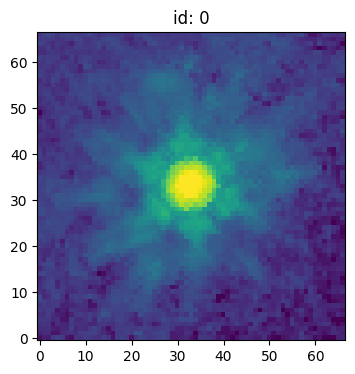

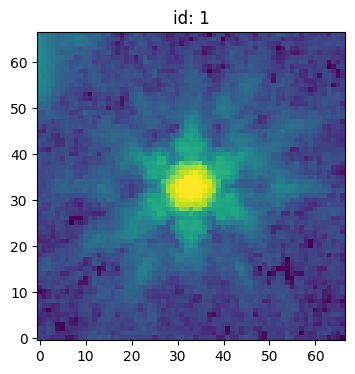

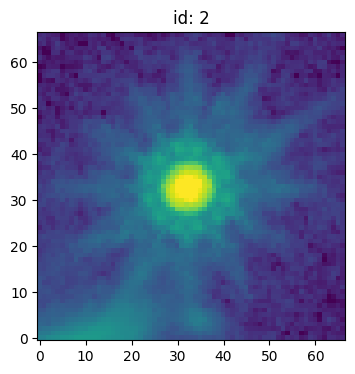

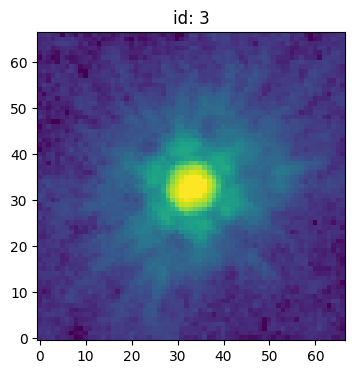

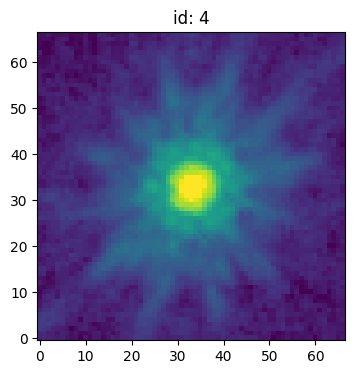

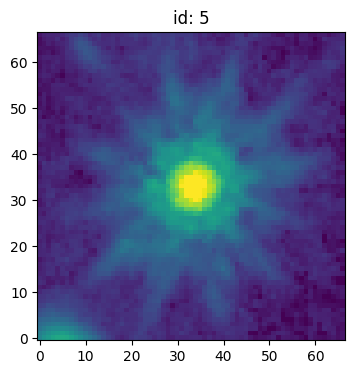

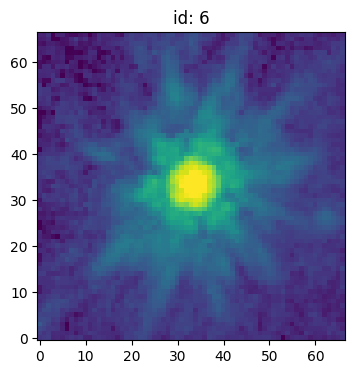

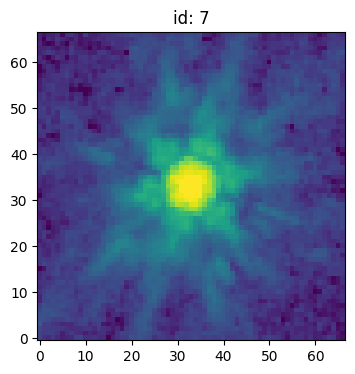

In [ ]:
#idx_incld = np.asarray([13, 14, 32, 40, 41, 57, 162, 179, 212, 233])
idx_incld = np.asarray([19, 21, 22, 35, 40, 44, 49, 50])

mask = [False for i in range(len(peaks_tbl['x_peak']))]
for ii in range(len(idx_incld)):
    mask[int(idx_incld[ii])] = True
    
stars_tbl = Table()
stars_tbl['x'] = peaks_tbl['x_peak'][mask]  
stars_tbl['y'] = peaks_tbl['y_peak'][mask]

nddata = NDData(data=data_sci)
stars = extract_stars(nddata, stars_tbl, size=psf_size[int(id_fil)]) 

for ii in range(0,len(stars)):
    plt.figure(figsize=(4,4))
    plt.subplot()
    norm = simple_norm(stars[ii], 'log', percent=99.)
    plt.imshow(stars[ii], norm=norm, origin='lower', cmap='viridis')
    plt.title('id: %d' % ii)

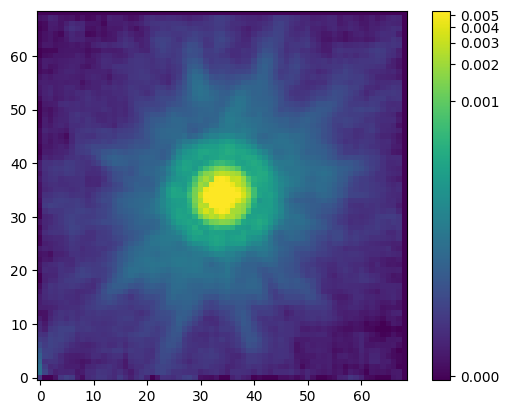

In [31]:
epsf_builder = EPSFBuilder(oversampling=1, maxiters=3, progress_bar=False)  
epsf, fitted_stars = epsf_builder(stars) 

norm = simple_norm(epsf.data, 'log', percent=99.)
plt.imshow(epsf.data, norm=norm, origin='lower', cmap='viridis')
plt.colorbar()
plt.show()


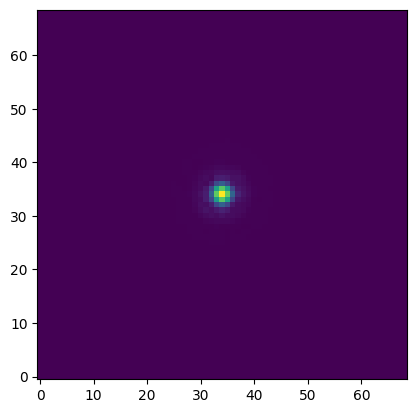

In [32]:
name_out = 'PSF_ABELL2744_JWST_%s.fits' % fil_names[int(id_fil)]
fits.writeto(name_out, epsf.data, overwrite=True)

hdu = fits.open(name_out)
plt.imshow(hdu[0].data, origin='lower')
plt.show()
hdu.close()

### (2) PSF of JWST/F115W

In [69]:
id_fil = 1
print (filters[int(id_fil)])

hdu = fits.open(dir_images+sci_img[filters[int(id_fil)]])
data_sci = hdu[0].data
hdu.close()

hdu = fits.open(dir_images+wht_img[filters[int(id_fil)]])
data_err = 1.0/np.sqrt(hdu[0].data)
hdu.close()

peaks_tbl = find_peaks(data_sci, threshold=80.0, error=data_err) 
peaks_tbl['peak_value'].info.format = '%.8g'  # for consistent table output 
print(peaks_tbl)

print ('Number of stars: %d' % len(peaks_tbl['x_peak']))

jwst_nircam_f444w
 id x_peak y_peak peak_value
--- ------ ------ ----------
  1   4357    152  97.502113
  2   4359    152  99.695526
  3   4357    154  111.04314
  4   4359    154   120.2582
  5   3324    445  100.18282
  6   5706    716  80.480133
  7   5715    721  93.999748
  8   5710    722  83.716576
  9   5234   2265   83.25264
 10   2323   2548  105.36614
...    ...    ...        ...
 51   7968   9347  109.06068
 52  10152   9485  88.677979
 53  13133  10262  92.645325
 54  11231  10854   105.5379
 55  11881  10942  111.18491
 56  12074  11259  81.170959
 57   9167  11840  80.494492
 58   7291  12111  93.750229
 59   9168  12376  132.68874
 60  16022  14100  239.55986
Length = 60 rows
Number of stars: 60


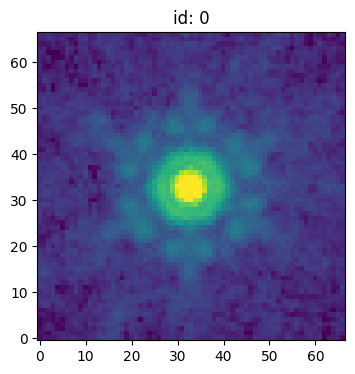

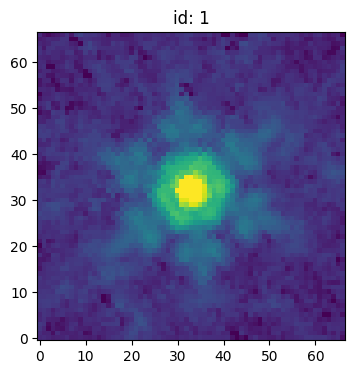

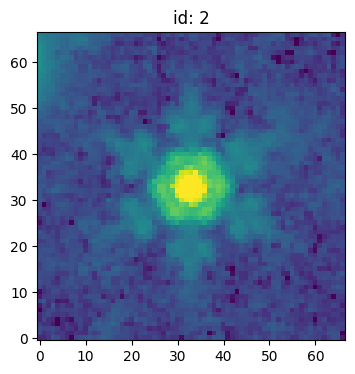

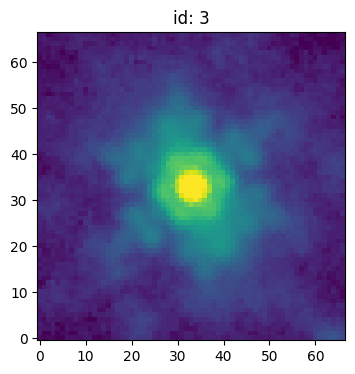

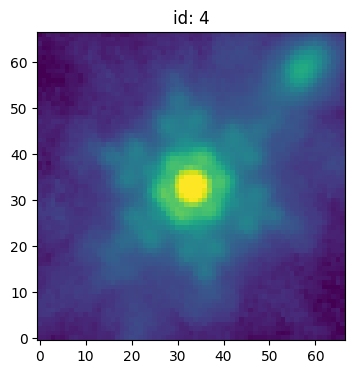

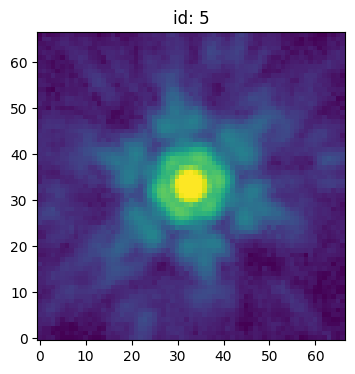

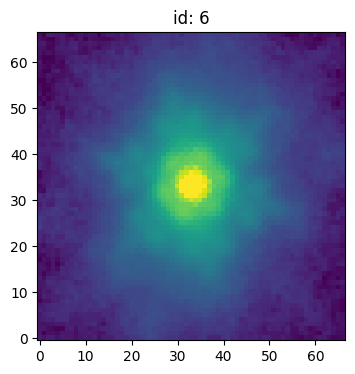

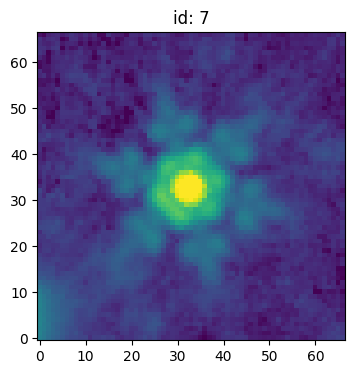

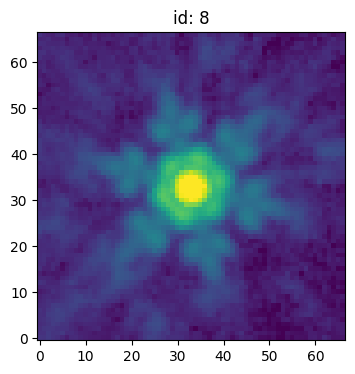

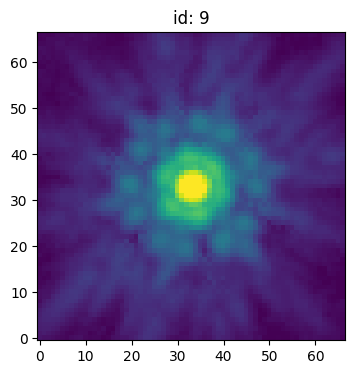

In [ ]:
idx_incld = np.asarray([9, 18, 19, 20, 21, 22, 26, 57, 58, 59]) 


mask = [False for i in range(len(peaks_tbl['x_peak']))]
for ii in range(len(idx_incld)):
    mask[int(idx_incld[ii])] = True
    
stars_tbl = Table()
stars_tbl['x'] = peaks_tbl['x_peak'][mask]  
stars_tbl['y'] = peaks_tbl['y_peak'][mask]

'''
from astropy.stats import sigma_clipped_stats
mean_val, median_val, std_val = sigma_clipped_stats(data_sci, sigma=2.0)
data_sci -= median_val
'''

nddata = NDData(data=data_sci)
stars = extract_stars(nddata, stars_tbl, size=psf_size[int(id_fil)]) 

for ii in range(0,len(stars)):
    plt.figure(figsize=(4,4))
    plt.subplot()
    norm = simple_norm(stars[ii], 'log', percent=99.)
    plt.imshow(stars[ii], norm=norm, origin='lower', cmap='viridis')
    plt.title('id: %d' % ii)

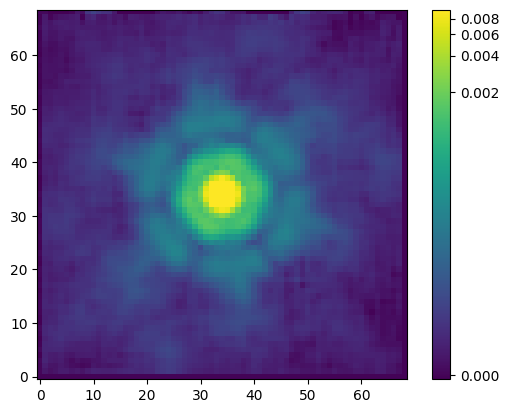

In [78]:
epsf_builder = EPSFBuilder(oversampling=1, maxiters= 3, progress_bar=False)  
epsf, fitted_stars = epsf_builder(stars) 

norm = simple_norm(epsf.data, 'log', percent = 99.)
plt.imshow(epsf.data, norm=norm, origin='lower', cmap='viridis')
plt.colorbar()

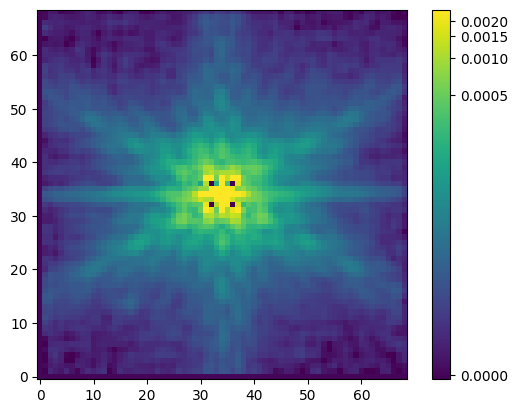

In [274]:
from photutils.psf import EPSFStars  # Import the container class

# 1. Filter out bad star snapshot objects manually
vetted_stars_list = []
for i, star in enumerate(stars):
    # Skip if the star contains NaNs/infs 
    if np.isnan(star.data).any():
        continue
    
    # Skip if the star peak is saturated 
    # (Adjust 50000 based on your image's specific saturation limit)
    if np.max(star.data) > 50000: 
        continue
    
    # Skip if the brightest pixel isn't roughly in the center of the cutout
    center = star.data.shape[0] // 2
    if np.argmax(star.data) != (center * star.data.shape[1] + center):
        continue
        
    vetted_stars_list.append(star)

# 2. CRITICAL STEP: Wrap your python list back into an EPSFStars object
clean_stars = EPSFStars(vetted_stars_list)

epsf_builder = EPSFBuilder(oversampling=1, maxiters=2, progress_bar=False)  
epsf, fitted_stars = epsf_builder(clean_stars) 

norm = simple_norm(epsf.data, 'log', percent = 99.)
plt.imshow(epsf.data, norm=norm, origin='lower', cmap='viridis')
plt.colorbar()

In [135]:
# Check if any input star has NaNs near its center
for i, star in enumerate(stars):
    if np.isnan(star.data).any():
        print(f"Star {i} contains NaN values!")

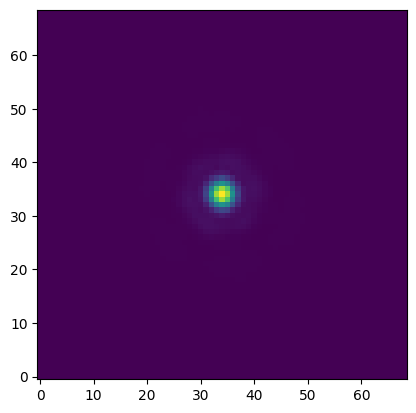

In [79]:
name_out = 'PSF_ABELL2744_%s.fits' % fil_names[int(id_fil)]
fits.writeto(name_out, epsf.data, overwrite=True)

hdu = fits.open(name_out)
plt.imshow(hdu[0].data, origin='lower')
hdu.close()

In [ ]:
id_fil = 1
print (filters[int(id_fil)])

hdu = fits.open(dir_images+sci_img[filters[int(id_fil)]])
data_sci = hdu[0].data
hdu.close()

hdu = fits.open(dir_images+wht_img[filters[int(id_fil)]])
data_err = 1.0/np.sqrt(hdu[0].data)
hdu.close()

peaks_tbl = find_peaks(data_sci, threshold=200.0, error=data_err) 
peaks_tbl['peak_value'].info.format = '%.8g'  # for consistent table output 
print(peaks_tbl)

print ('Number of stars: %d' % len(peaks_tbl['x_peak']))

idx_incld = np.asarray([3, 11, 55, 56, 59, 60, 66, 69, 
                        73, 76, 77, 81, 95, 96, 99, 100, 
                        107, 117, 119, 120, 122, 127, 158, 159, 
                        172, 173, 204, 210, 215, 216, 217, 247,
                        248, 296, 298, 299, 300, 301, 302, 
                        306, 307, 311, 318, 334, 335, 336, 337, 338, 341,
                        346,348, 349, 350, 352, 353, 358, 360, 
                        389, 399, 400, 402, 404, 
                        405, 406, 407, 410, 412, 
                        445,  451, 455])




mask = [False for i in range(len(peaks_tbl['x_peak']))]
for ii in range(len(idx_incld)):
    mask[int(idx_incld[ii])] = True
    
stars_tbl = Table()
stars_tbl['x'] = peaks_tbl['x_peak'][mask]  
stars_tbl['y'] = peaks_tbl['y_peak'][mask]

nddata = NDData(data=data_sci)
stars = extract_stars(nddata, stars_tbl, size=psf_size[int(id_fil)]) 

for ii in range(0,len(stars)):
    plt.figure(figsize=(4,4))
    plt.subplot()
    norm = simple_norm(stars[ii], 'log', percent=99.)
    plt.imshow(stars[ii], norm=norm, origin='lower', cmap='Blues')
    plt.title('id: %d' % ii)

epsf_builder = EPSFBuilder(oversampling=1, maxiters=2, progress_bar=False)  
epsf, fitted_stars = epsf_builder(stars) 

norm = simple_norm(epsf.data, 'log', percent = 99.)
plt.imshow(epsf.data, norm=norm, origin='lower', cmap='viridis')
plt.colorbar()

name_out = 'PSF_Ceers_new_%s.fits' % fil_names[int(id_fil)]
fits.writeto(name_out, epsf.data, overwrite=True)

hdu = fits.open(name_out)
plt.imshow(hdu[0].data, origin='lower')
hdu.close()

### (3) JWST/F150W

In [ ]:
id_fil = 2
print (filters[int(id_fil)])

hdu = fits.open(dir_images+sci_img[filters[int(id_fil)]])
data_sci = hdu[0].data
hdu.close()

hdu = fits.open(dir_images+wht_img[filters[int(id_fil)]])
data_err = 1.0/np.sqrt(hdu[0].data)
hdu.close()

peaks_tbl = find_peaks(data_sci, threshold=200.0, error=data_err) 
peaks_tbl['peak_value'].info.format = '%.8g'  # for consistent table output 
print(peaks_tbl)

print ('Number of stars: %d' % len(peaks_tbl['x_peak']))

jwst_nircam_f150w
 id x_peak y_peak peak_value
--- ------ ------ ----------
  1   1123    155  200.71414
  2   1421    462   215.4966
  3   7873    622  258.93332
  4   7870    623  275.37418
  5   7872    625  402.56503
  6    919    827  319.99158
  7    909    831  829.38812
  8    913    831  767.25293
  9    915    833  962.12927
 10    907    834  749.40332
...    ...    ...        ...
569   1887  28947  532.28259
570   1879  28948  433.99832
571   1873  28949  490.93979
572   1885  28949  467.71161
573   1892  28949  517.71442
574   1893  28951  525.15155
575   1889  28952  297.85287
576   1893  28957  284.10092
577   1893  28959  287.41858
578   1638  29834   355.7178
Length = 578 rows
Number of stars: 578


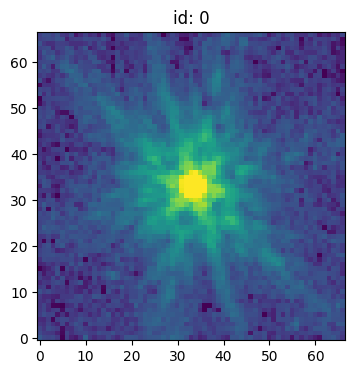

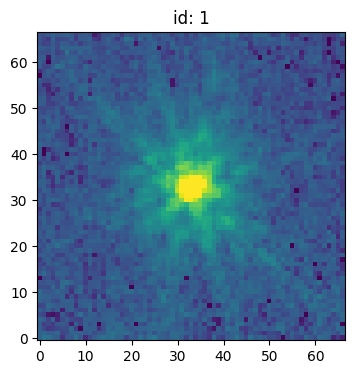

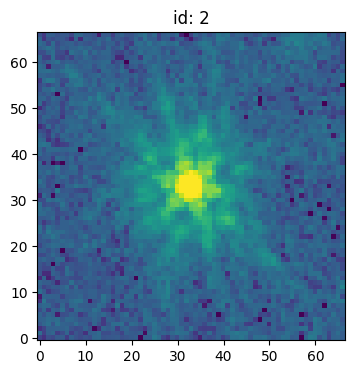

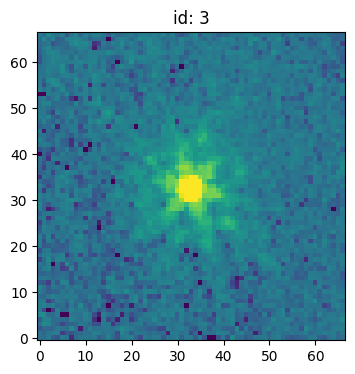

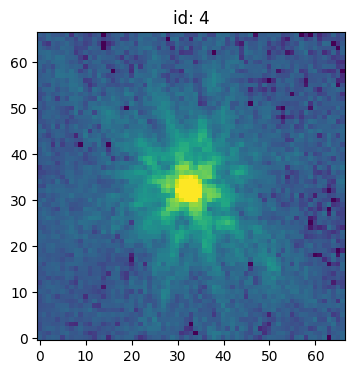

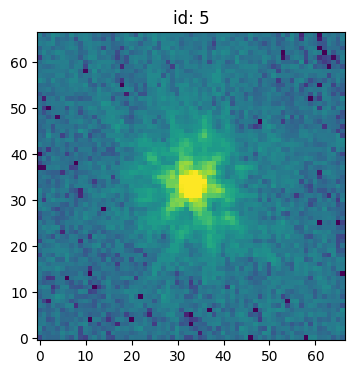

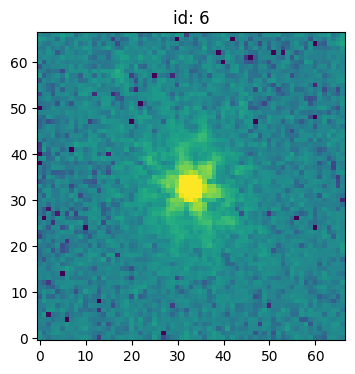

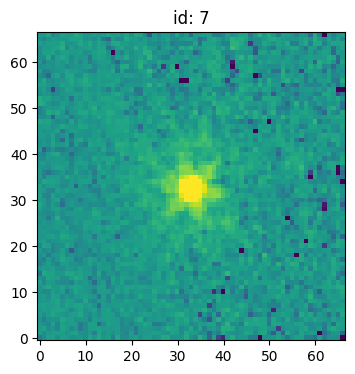

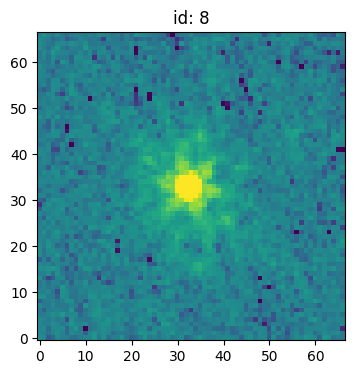

In [ ]:
idx_incld = np.asarray([26, 84, 85, 87, 141, 142, 143, 160, 162])

mask = [False for i in range(len(peaks_tbl['x_peak']))]
for ii in range(len(idx_incld)):
    mask[int(idx_incld[ii])] = True
    
stars_tbl = Table()
stars_tbl['x'] = peaks_tbl['x_peak'][mask]  
stars_tbl['y'] = peaks_tbl['y_peak'][mask]

nddata = NDData(data=data_sci)
stars = extract_stars(nddata, stars_tbl, size=psf_size[int(id_fil)]) 

for ii in range(0,len(stars)):
    plt.figure(figsize=(4,4))
    plt.subplot()
    norm = simple_norm(stars[ii], 'log', percent=99.)
    plt.imshow(stars[ii], norm=norm, origin='lower', cmap='viridis')
    plt.title('id: %d' % ii)

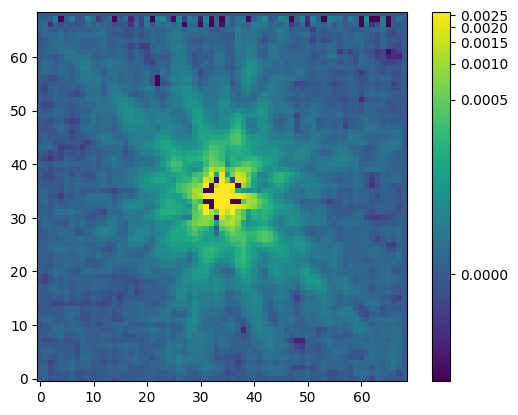

In [ ]:
epsf_builder = EPSFBuilder(oversampling=1, maxiters=3, progress_bar=False)  
epsf, fitted_stars = epsf_builder(stars) 

norm = simple_norm(epsf.data, 'log', percent=99.)
plt.imshow(epsf.data, norm=norm, origin='lower', cmap='viridis')
plt.colorbar()

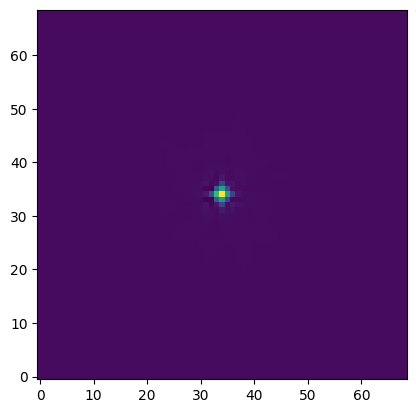

In [ ]:
name_out = 'PSF_West_%s.fits' % fil_names[int(id_fil)]
fits.writeto(name_out, epsf.data, overwrite=True)

hdu = fits.open(name_out)
plt.imshow(hdu[0].data, origin='lower')
hdu.close()

### (4) JWST/F200W

In [ ]:
id_fil = 3
print (filters[int(id_fil)])

hdu = fits.open(dir_images+sci_img[filters[int(id_fil)]])
data_sci = hdu[0].data
hdu.close()

hdu = fits.open(dir_images+wht_img[filters[int(id_fil)]])
data_err = 1.0/np.sqrt(hdu[0].data)
hdu.close()

peaks_tbl = find_peaks(data_sci, threshold=200.0, error=data_err) 
peaks_tbl['peak_value'].info.format = '%.8g'  # for consistent table output 
print(peaks_tbl)

print ('Number of stars: %d' % len(peaks_tbl['x_peak']))

jwst_nircam_f200w
 id x_peak y_peak peak_value
--- ------ ------ ----------
  1   2385   2416  755.45026
  2   2387   2417   690.5379
  3   2383   2418  531.72949
  4   2387   2419  627.28729
  5   2383   2420  594.18811
  6   2386   2421  658.89307
  7   1891   3574   828.9129
  8   1908   3588  379.27835
  9   1907   3591  300.82993
 10   2314   4015   627.3288
...    ...    ...        ...
379   1877  28946  591.95532
380   1881  28946  513.34668
381   1887  28946  436.60791
382   1900  28946  467.95978
383   1884  28948  631.00977
384   1894  28948   298.1105
385   1892  28950  512.45422
386   1884  28951  564.37152
387   1868  28953  210.56133
388   1638  29834  439.33774
Length = 388 rows
Number of stars: 388


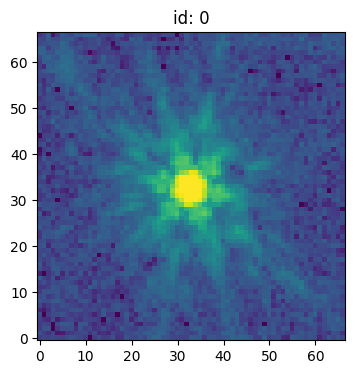

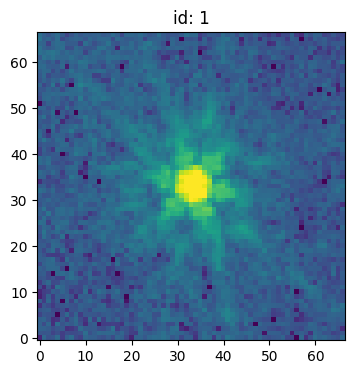

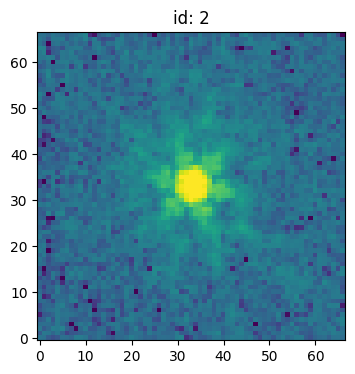

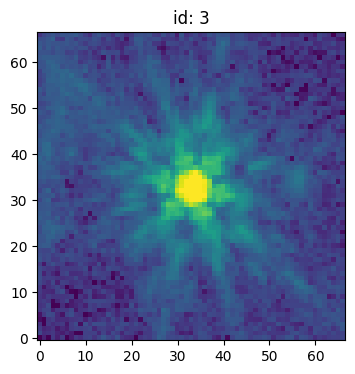

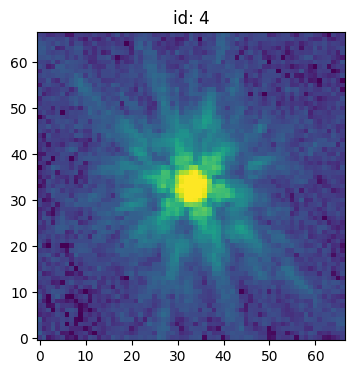

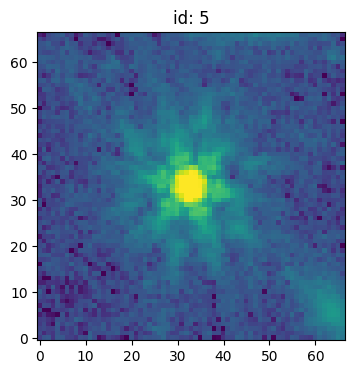

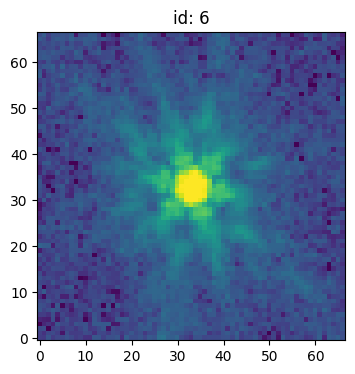

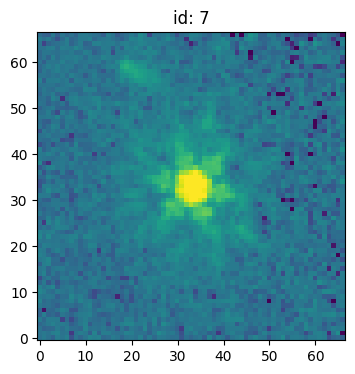

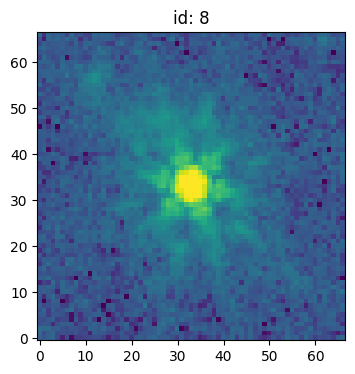

In [ ]:
idx_incld = np.asarray([36, 37, 60, 83, 112, 113, 134, 143, 144])

mask = [False for i in range(len(peaks_tbl['x_peak']))]
for ii in range(len(idx_incld)):
    mask[int(idx_incld[ii])] = True
    
stars_tbl = Table()
stars_tbl['x'] = peaks_tbl['x_peak'][mask]  
stars_tbl['y'] = peaks_tbl['y_peak'][mask]

nddata = NDData(data=data_sci)
stars = extract_stars(nddata, stars_tbl, size=psf_size[int(id_fil)]) 

for ii in range(0,len(stars)):
    plt.figure(figsize=(4,4))
    plt.subplot()
    norm = simple_norm(stars[ii], 'log', percent=99.)
    plt.imshow(stars[ii], norm=norm, origin='lower', cmap='viridis')
    plt.title('id: %d' % ii)

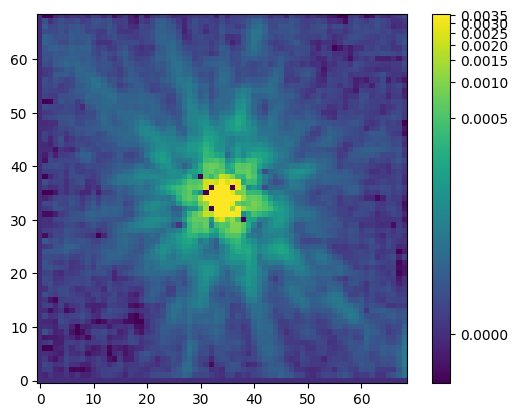

In [ ]:
epsf_builder = EPSFBuilder(oversampling=1, maxiters=3, progress_bar=False)  
epsf, fitted_stars = epsf_builder(stars) 

norm = simple_norm(epsf.data, 'log', percent=99.)
plt.imshow(epsf.data, norm=norm, origin='lower', cmap='viridis')
plt.colorbar()

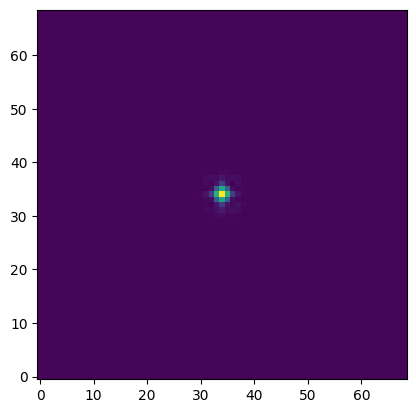

In [ ]:
name_out = 'PSF_West_%s.fits' % fil_names[int(id_fil)]
fits.writeto(name_out, epsf.data, overwrite=True)

hdu = fits.open(name_out)
plt.imshow(hdu[0].data, origin='lower')
hdu.close()

### (5) JWST/F277W

In [ ]:
id_fil = 4
print (filters[int(id_fil)])

hdu = fits.open(dir_images+sci_img[filters[int(id_fil)]])
data_sci = hdu[0].data
hdu.close()

hdu = fits.open(dir_images+wht_img[filters[int(id_fil)]])
data_err = 1.0/np.sqrt(hdu[0].data)
hdu.close()

peaks_tbl = find_peaks(data_sci, threshold=120.0, error=data_err) 
peaks_tbl['peak_value'].info.format = '%.8g'  # for consistent table output 
print(peaks_tbl)

print ('Number of stars: %d' % len(peaks_tbl['x_peak']))

jwst_nircam_f277w
 id x_peak y_peak peak_value
--- ------ ------ ----------
  1   4466     55  232.44995
  2   4817    518  223.56499
  3   9404    905  330.32498
  4   2311    969  120.34595
  5   2315    981   124.7337
  6   8377   1172  331.56854
  7   8376   1175  412.71429
  8   7855   1271  194.17731
  9   7863   1272  188.76604
 10   7848   1275  385.83694
...    ...    ...        ...
242   1874  28940  121.19706
243   1875  28948  185.88232
244   1898  28948  172.27544
245   1878  28949  121.82716
246   1882  28950   220.0719
247   1882  28956  122.94834
248   1637  29833  139.69016
249   1639  29835  143.64648
250   2275  30615  174.93266
251    898  32597  159.26326
Length = 251 rows
Number of stars: 251


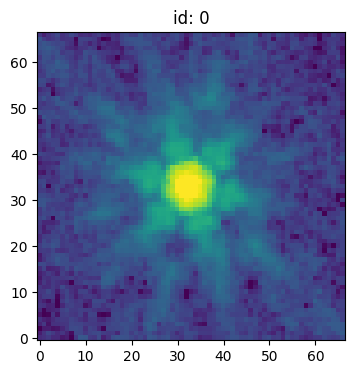

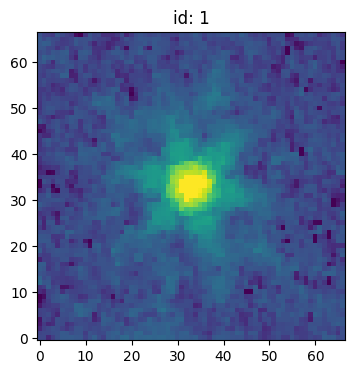

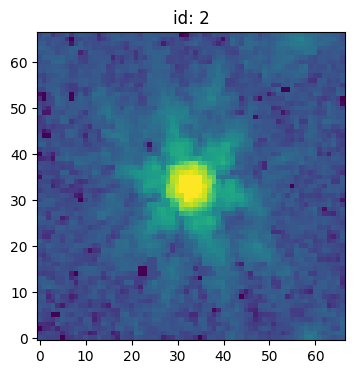

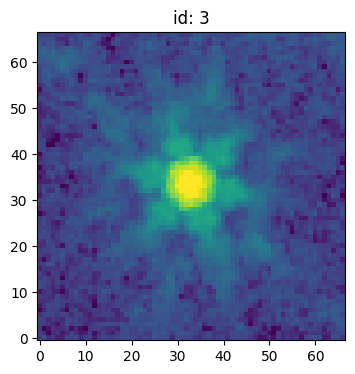

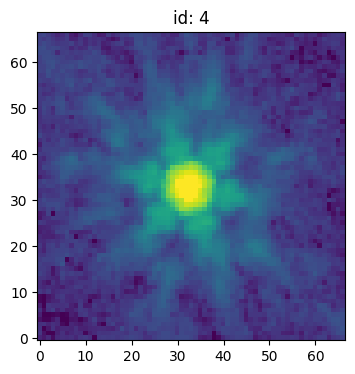

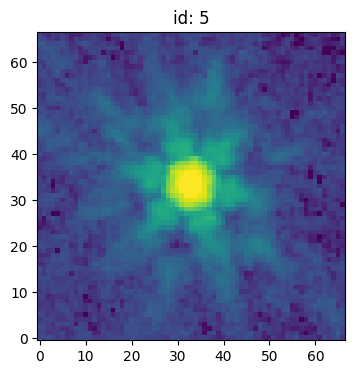

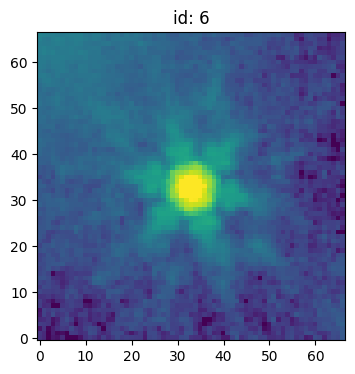

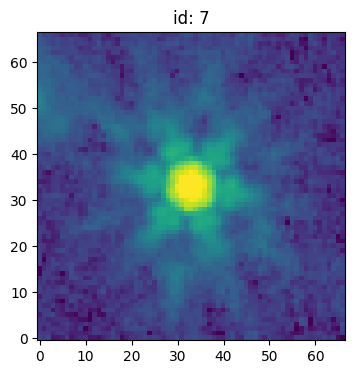

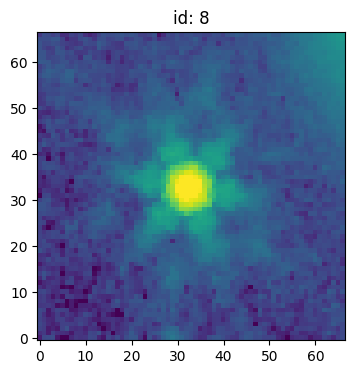

In [ ]:
idx_incld = np.asarray([2, 35, 36, 61, 76, 77, 125, 197, 203])

mask = [False for i in range(len(peaks_tbl['x_peak']))]
for ii in range(len(idx_incld)):
    mask[int(idx_incld[ii])] = True
    
stars_tbl = Table()
stars_tbl['x'] = peaks_tbl['x_peak'][mask]  
stars_tbl['y'] = peaks_tbl['y_peak'][mask]

nddata = NDData(data=data_sci)
stars = extract_stars(nddata, stars_tbl, size=psf_size[int(id_fil)]) 

for ii in range(0,len(stars)):
    plt.figure(figsize=(4,4))
    plt.subplot()
    norm = simple_norm(stars[ii], 'log', percent=99.)
    plt.imshow(stars[ii], norm=norm, origin='lower', cmap='viridis')
    plt.title('id: %d' % ii)

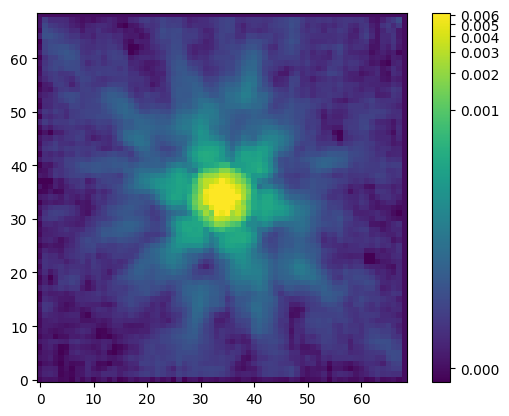

In [ ]:
epsf_builder = EPSFBuilder(oversampling=1, maxiters=3, progress_bar=False)  
epsf, fitted_stars = epsf_builder(stars) 

norm = simple_norm(epsf.data, 'log', percent=99.)
plt.imshow(epsf.data, norm=norm, origin='lower', cmap='viridis')
plt.colorbar()

In [ ]:
name_out = 'PSF_West_%s.fits' % fil_names[int(id_fil)]
fits.writeto(name_out, epsf.data, overwrite=True)

hdu = fits.open(name_out)
plt.imshow(hdu[0].data, origin='lower', norm=norm,)
hdu.close()

NameError: name 'fil_names' is not defined

### (6) JWST/F356W

In [ ]:
id_fil = 5
print (filters[int(id_fil)])

hdu = fits.open(dir_images+sci_img[filters[int(id_fil)]])
data_sci = hdu[0].data
hdu.close()

hdu = fits.open(dir_images+wht_img[filters[int(id_fil)]])
data_err = 1.0/np.sqrt(hdu[0].data)
hdu.close()

peaks_tbl = find_peaks(data_sci, threshold=120.0, error=data_err) 
peaks_tbl['peak_value'].info.format = '%.8g'  # for consistent table output 
print(peaks_tbl)

print ('Number of stars: %d' % len(peaks_tbl['x_peak']))

jwst_nircam_f356w
 id x_peak y_peak peak_value
--- ------ ------ ----------
  1   2574   3363  176.17348
  2   1892   3574  122.97145
  3     47   4191  121.62157
  4     50   4192  125.56596
  5     51   4192  125.56596
  6     51   4193  125.56596
  7     42   4196  160.63162
  8     49   4202  141.51379
  9     50   4202  141.51379
 10     48   4203  141.51379
...    ...    ...        ...
104   3912  23995  139.99329
105   3087  25033  141.63147
106   3087  25034  141.63147
107   2775  25202  125.35542
108   1418  26545   168.7435
109   1567  28279  162.39886
110   1897  28922  176.09267
111   1884  28951  155.46236
112   1638  29835   154.7189
113   1173  30036  163.29779
Length = 113 rows
Number of stars: 113


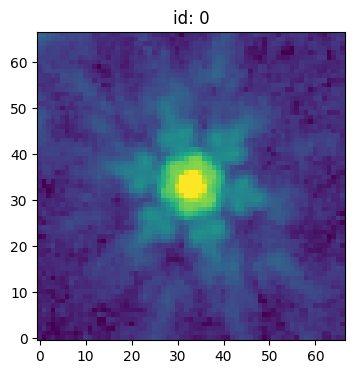

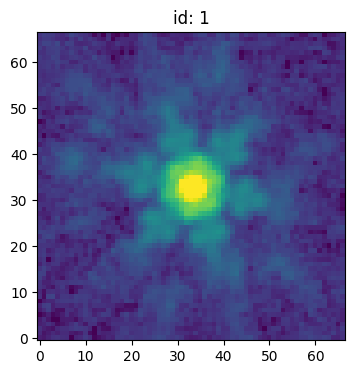

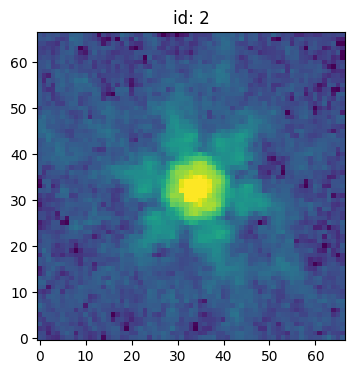

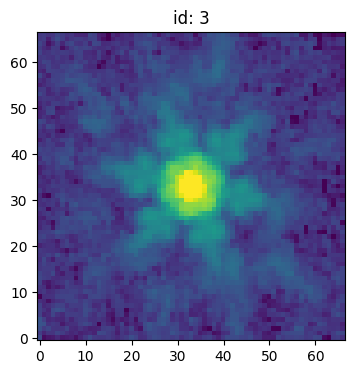

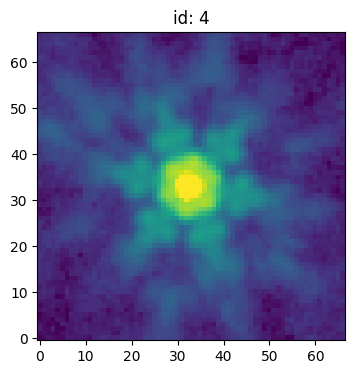

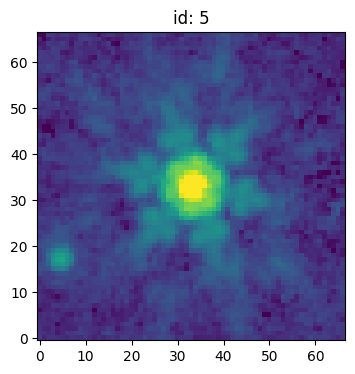

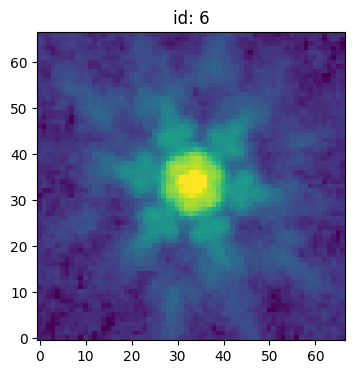

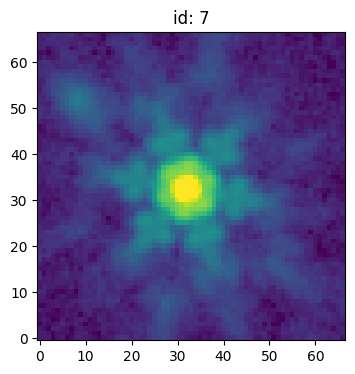

In [ ]:
idx_incld = np.asarray([19, 21, 22, 33, 43, 44, 51, 53])

mask = [False for i in range(len(peaks_tbl['x_peak']))]
for ii in range(len(idx_incld)):
    mask[int(idx_incld[ii])] = True
    
stars_tbl = Table()
stars_tbl['x'] = peaks_tbl['x_peak'][mask]  
stars_tbl['y'] = peaks_tbl['y_peak'][mask]

nddata = NDData(data=data_sci)
stars = extract_stars(nddata, stars_tbl, size=psf_size[int(id_fil)]) 

for ii in range(0,len(stars)):
    plt.figure(figsize=(4,4))
    plt.subplot()
    norm = simple_norm(stars[ii], 'log', percent=99.)
    plt.imshow(stars[ii], norm=norm, origin='lower', cmap='viridis')
    plt.title('id: %d' % ii)

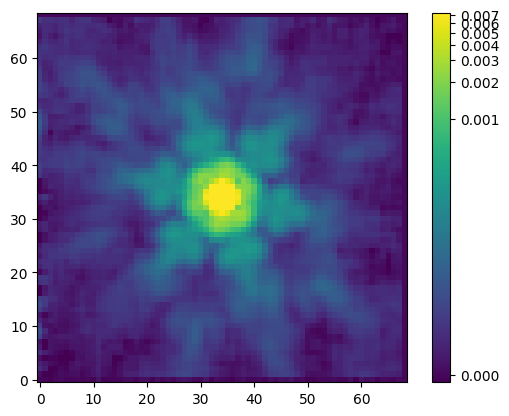

In [ ]:
epsf_builder = EPSFBuilder(oversampling=1, maxiters=3, progress_bar=False)  
epsf, fitted_stars = epsf_builder(stars) 

norm = simple_norm(epsf.data, 'log', percent=99.)
plt.imshow(epsf.data, norm=norm, origin='lower', cmap='viridis')
plt.colorbar()

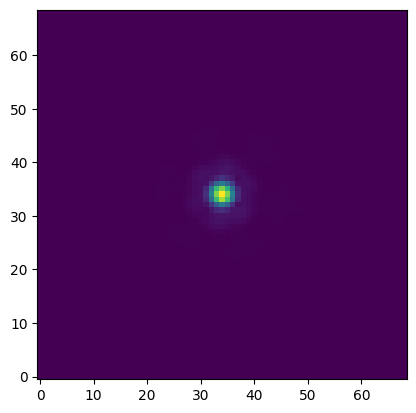

In [ ]:
name_out = 'PSF_West_%s.fits' % fil_names[int(id_fil)]
fits.writeto(name_out, epsf.data, overwrite=True)

hdu = fits.open(name_out)
plt.imshow(hdu[0].data, origin='lower')
hdu.close()

### (7) JWST/F410M

In [ ]:
id_fil = 6
print (filters[int(id_fil)])

hdu = fits.open(dir_images+sci_img[filters[int(id_fil)]])
data_sci = hdu[0].data
hdu.close()

hdu = fits.open(dir_images+wht_img[filters[int(id_fil)]])
data_err = 1.0/np.sqrt(hdu[0].data)
hdu.close()

peaks_tbl = find_peaks(data_sci, threshold=100.0, error=data_err) 
peaks_tbl['peak_value'].info.format = '%.8g'  # for consistent table output 
print(peaks_tbl)

print ('Number of stars: %d' % len(peaks_tbl['x_peak']))

jwst_nircam_f410m
 id x_peak y_peak peak_value
--- ------ ------ ----------
  1   2573   3363  254.38484
  2   1032   3543  258.52325
  3   1907   3589  335.21225
  4   2317   4015  262.35724
  5   2312   4016  345.30313
  6   2317   4016  262.35724
  7   2309   4019  383.40817
  8   2320   4023  173.16216
  9   2318   4024  274.23026
 10   2309   4025  390.87466
...    ...    ...        ...
204   1899  28945  229.67513
205   1884  28946  392.59296
206   1896  28947  249.83829
207   1888  28949  225.94826
208   1900  28949   231.8307
209   1884  28951  130.53621
210   1882  28955  107.00307
211   1193  29229  120.16453
212   1638  29834  122.45986
213   1173  30035  114.94878
Length = 213 rows
Number of stars: 213


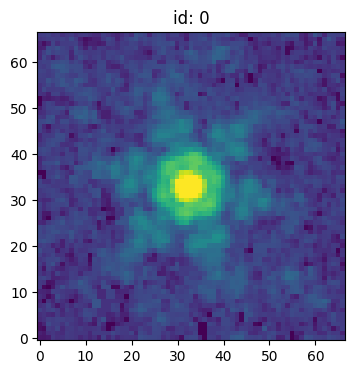

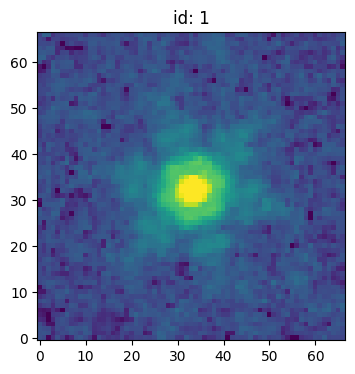

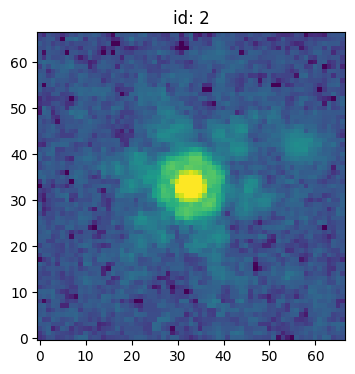

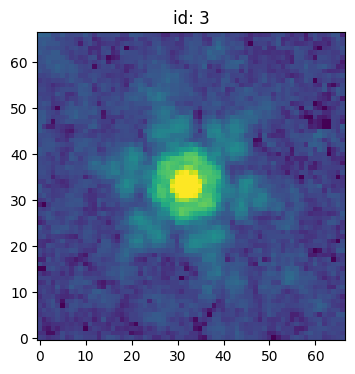

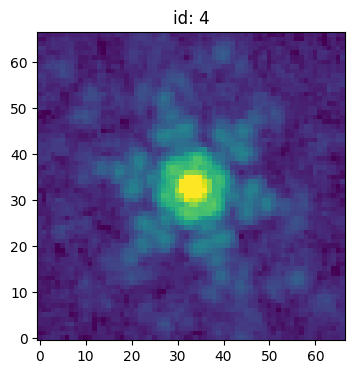

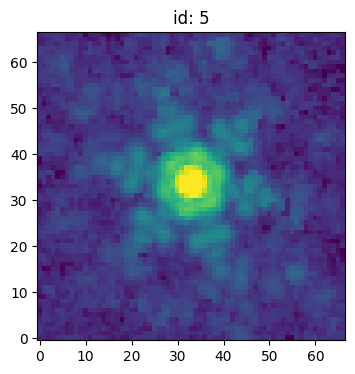

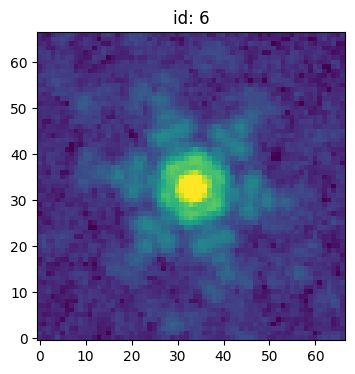

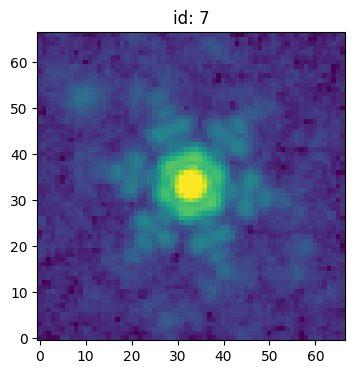

In [ ]:
idx_incld = np.asarray([0, 21, 23, 27, 47, 48, 124, 127])

mask = [False for i in range(len(peaks_tbl['x_peak']))]
for ii in range(len(idx_incld)):
    mask[int(idx_incld[ii])] = True
    
stars_tbl = Table()
stars_tbl['x'] = peaks_tbl['x_peak'][mask]  
stars_tbl['y'] = peaks_tbl['y_peak'][mask]

nddata = NDData(data=data_sci)
stars = extract_stars(nddata, stars_tbl, size=psf_size[int(id_fil)]) 

for ii in range(0,len(stars)):
    plt.figure(figsize=(4,4))
    plt.subplot()
    norm = simple_norm(stars[ii], 'log', percent=99.)
    plt.imshow(stars[ii], norm=norm, origin='lower', cmap='viridis')
    plt.title('id: %d' % ii)

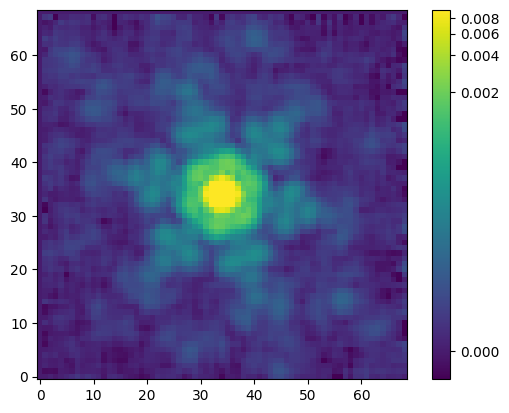

In [ ]:
epsf_builder = EPSFBuilder(oversampling=1, maxiters=3, progress_bar=False)  
epsf, fitted_stars = epsf_builder(stars) 

norm = simple_norm(epsf.data, 'log', percent=99.)
plt.imshow(epsf.data, norm=norm, origin='lower', cmap='viridis')
plt.colorbar()

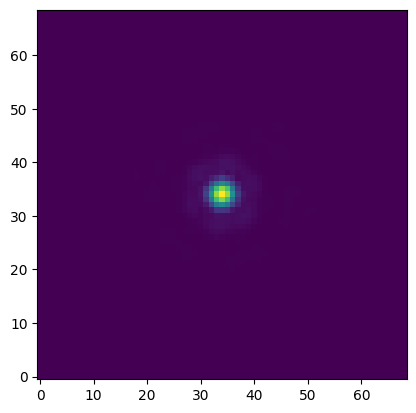

In [ ]:
name_out = 'PSF_West_%s.fits' % fil_names[int(id_fil)]
fits.writeto(name_out, epsf.data, overwrite=True)

hdu = fits.open(name_out)
plt.imshow(hdu[0].data, origin='lower')
hdu.close()

### (8) JWST/F444W

In [ ]:
id_fil = 7
print (filters[int(id_fil)])

hdu = fits.open(dir_images+sci_img[filters[int(id_fil)]])
data_sci = hdu[0].data
hdu.close()

hdu = fits.open(dir_images+wht_img[filters[int(id_fil)]])
data_err = 1.0/np.sqrt(hdu[0].data)
hdu.close()

peaks_tbl = find_peaks(data_sci, threshold=100.0, error=data_err) 
peaks_tbl['peak_value'].info.format = '%.8g'  # for consistent table output 
print(peaks_tbl)

print ('Number of stars: %d' % len(peaks_tbl['x_peak']))

jwst_nircam_f444w
 id x_peak y_peak peak_value
--- ------ ------ ----------
  1   1156    615  111.31071
  2   7872    623  295.61975
  3   6754    866  189.03358
  4   6759    867  180.02592
  5   6749    870  138.08012
  6   6245    873  265.12579
  7   6760    873  181.66513
  8   6751    875  219.32059
  9   6756    877  212.06587
 10   8376   1173  209.11415
...    ...    ...        ...
174   1876  28941  127.84393
175   1877  28941  127.84393
176   1901  28943  136.47894
177   1899  28945  156.43468
178   1896  28947  156.32393
179   1886  28948  150.64795
180   1887  28948  150.64795
181   1900  28949  128.58571
182   1193  29229   122.8618
183   1638  29834  108.02738
Length = 183 rows
Number of stars: 183


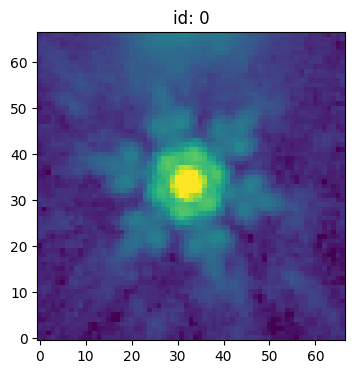

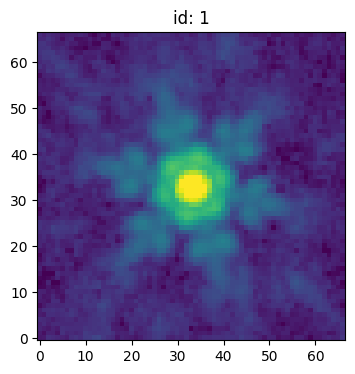

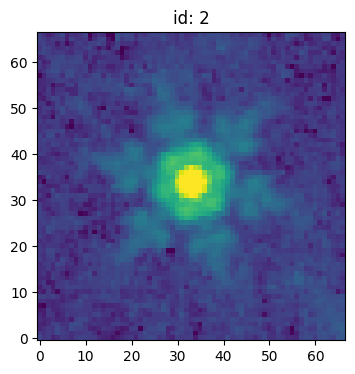

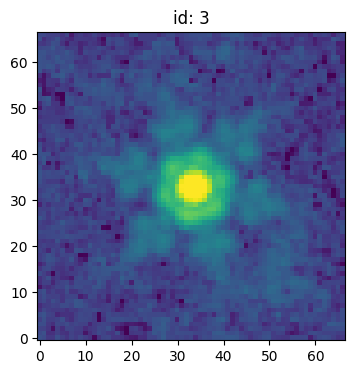

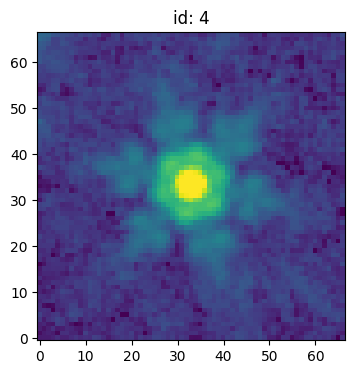

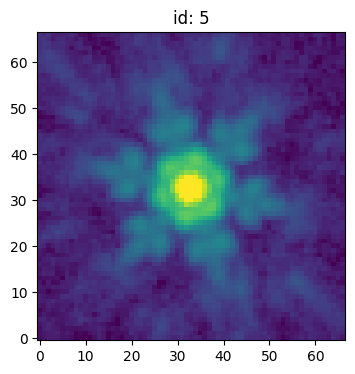

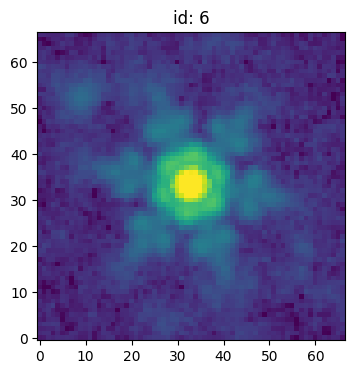

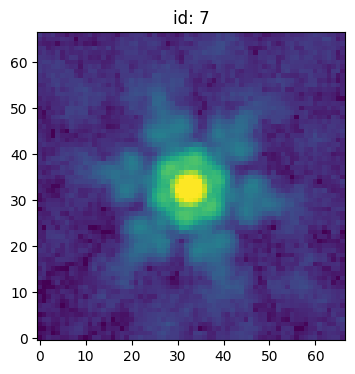

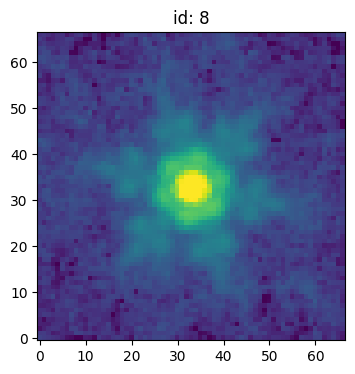

In [ ]:
idx_incld = np.asarray([1, 5, 32, 56, 60, 111, 122, 123, 143])

mask = [False for i in range(len(peaks_tbl['x_peak']))]
for ii in range(len(idx_incld)):
    mask[int(idx_incld[ii])] = True
    
stars_tbl = Table()
stars_tbl['x'] = peaks_tbl['x_peak'][mask]  
stars_tbl['y'] = peaks_tbl['y_peak'][mask]

nddata = NDData(data=data_sci)
stars = extract_stars(nddata, stars_tbl, size=psf_size[int(id_fil)]) 

for ii in range(0,len(stars)):
    plt.figure(figsize=(4,4))
    plt.subplot()
    norm = simple_norm(stars[ii], 'log', percent=99.)
    plt.imshow(stars[ii], norm=norm, origin='lower', cmap='viridis')
    plt.title('id: %d' % ii)

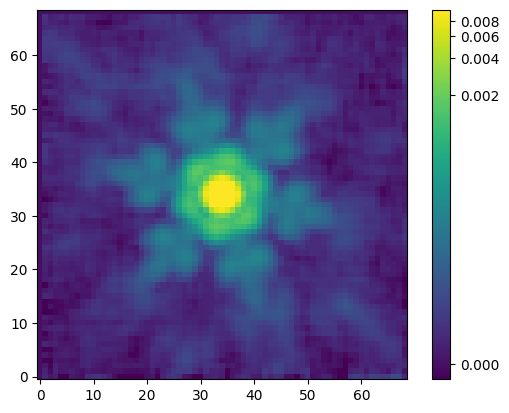

In [ ]:
epsf_builder = EPSFBuilder(oversampling=1, maxiters=3, progress_bar=False)  
epsf, fitted_stars = epsf_builder(stars) 

norm = simple_norm(epsf.data, 'log', percent=99.)
plt.imshow(epsf.data, norm=norm, origin='lower', cmap='viridis')
plt.colorbar()

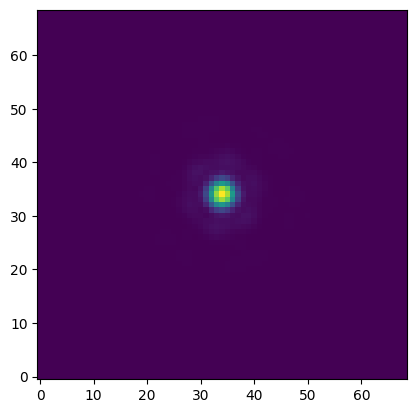

In [ ]:
name_out = 'PSF_West_%s.fits' % fil_names[int(id_fil)]
fits.writeto(name_out, epsf.data, overwrite=True)

hdu = fits.open(name_out)
plt.imshow(hdu[0].data, origin='lower')
hdu.close()

In [ ]:
interrupt

### HST 

In [ ]:
id_fil = 5
print (filters[int(id_fil)])

hdu = fits.open(dir_images+sci_img[filters[int(id_fil)]])
data_sci = hdu[0].data
hdu.close()

hdu = fits.open(dir_images+wht_img[filters[int(id_fil)]])
data_err = 1.0/np.sqrt(hdu[0].data)
hdu.close()

peaks_tbl = find_peaks(data_sci, threshold=400.0, error=data_err) 
peaks_tbl['peak_value'].info.format = '%.8g'  # for consistent table output 
print(peaks_tbl)

print ('Number of stars: %d' % len(peaks_tbl['x_peak']))

hst_acs_f775w
x_peak y_peak peak_value
------ ------ ----------
   676    101  642.90906
  1625   1879  1882.2142
  1628   1879  2261.8948
  1595   1880  425.97211
  1622   1880  2735.6963
  1619   1881  2632.0925
  1615   1882   2766.698
  1612   1883  2873.2463
  1601   1886  3296.9163
  1603   1886  3282.7253
   ...    ...        ...
  5976   8400  623.34021
  7869   8869  579.64319
  5445   8978  2091.5061
  7756   9121  2257.7673
  7759   9122  2312.0002
  7754   9124  2312.2454
  7756   9124     2317.2
  7751   9127  2287.8735
  7749   9129  2255.4944
  7746   9131  2187.5725
  5862   9211  590.31891
Length = 715 rows
Number of stars: 715


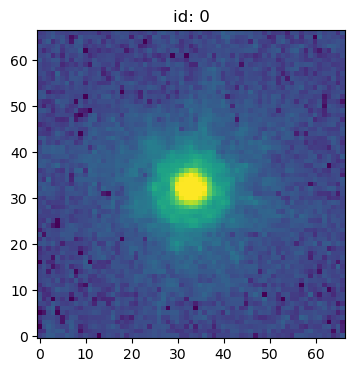

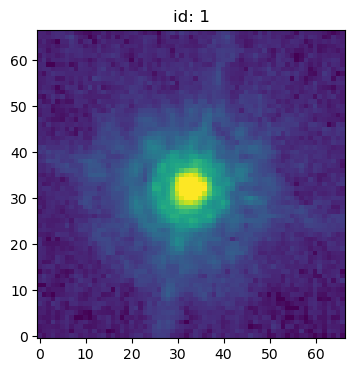

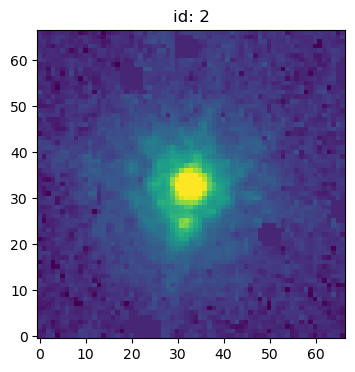

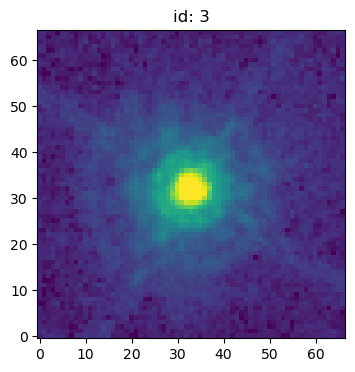

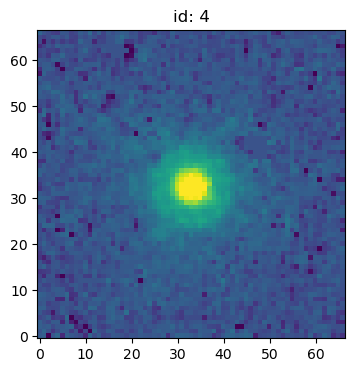

...

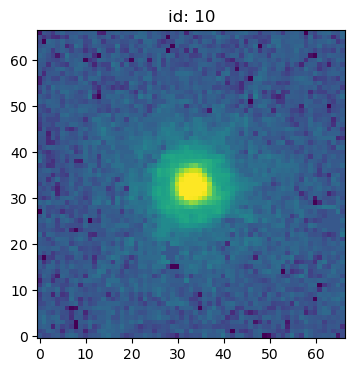

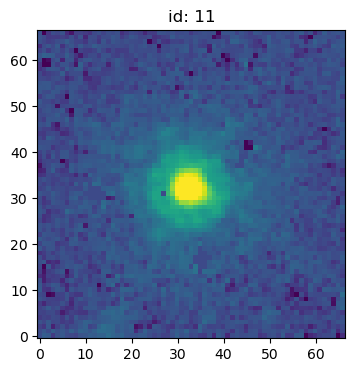

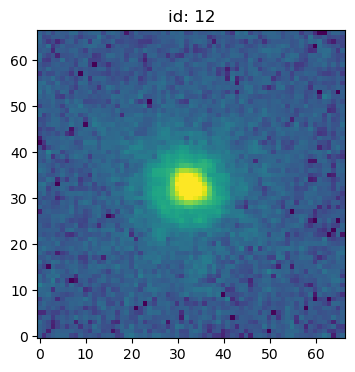

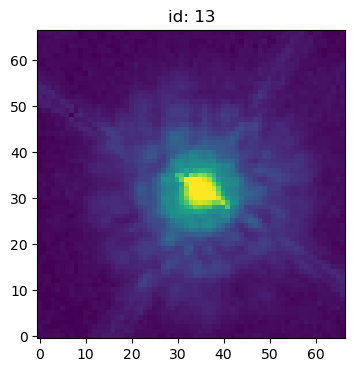

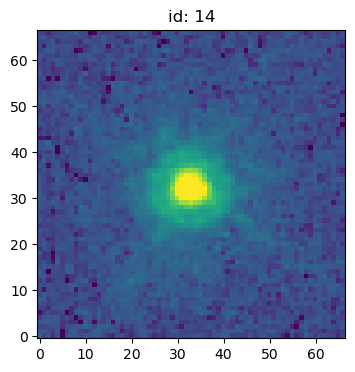

In [ ]:
idx_incld = np.asarray([0, 18, 48, 49, 101, 395, 666, 
                        700, 701, 702, 703, 704, 705, 706, 714])

mask = [False for i in range(len(peaks_tbl['x_peak']))]
for ii in range(len(idx_incld)):
    mask[int(idx_incld[ii])] = True
    
stars_tbl = Table()
stars_tbl['x'] = peaks_tbl['x_peak'][mask]  
stars_tbl['y'] = peaks_tbl['y_peak'][mask]

nddata = NDData(data=data_sci)
stars = extract_stars(nddata, stars_tbl, size=psf_size[int(id_fil)]) 

for ii in range(0,len(stars)):
    plt.figure(figsize=(4,4))
    plt.subplot()
    norm = simple_norm(stars[ii], 'log', percent=99.)
    plt.imshow(stars[ii], norm=norm, origin='lower', cmap='viridis')
    plt.title('id: %d' % ii)

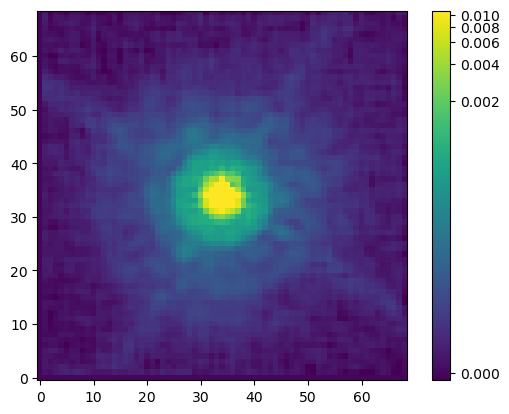

In [ ]:
epsf_builder = EPSFBuilder(oversampling=1, maxiters=3, progress_bar=False)  
epsf, fitted_stars = epsf_builder(stars) 

norm = simple_norm(epsf.data, 'log', percent=99.)
plt.imshow(epsf.data, norm=norm, origin='lower', cmap='viridis')
plt.colorbar()

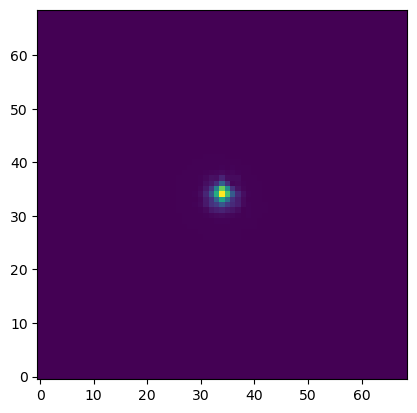

In [ ]:
name_out = 'PSF_%s.fits' % fil_names[int(id_fil)]
fits.writeto(name_out, epsf.data, overwrite=True)

hdu = fits.open(name_out)
plt.imshow(hdu[0].data, origin='lower')
hdu.close()

### (7) HST/F814W

In [ ]:
id_fil = 6
print (filters[int(id_fil)])

hdu = fits.open(dir_images+sci_img[filters[int(id_fil)]])
data_sci = hdu[0].data
hdu.close()

hdu = fits.open(dir_images+wht_img[filters[int(id_fil)]])
data_err = 1.0/np.sqrt(hdu[0].data)
hdu.close()

peaks_tbl = find_peaks(data_sci, threshold=100.0, error=data_err) 
peaks_tbl['peak_value'].info.format = '%.8g'  # for consistent table output 
print(peaks_tbl)

print ('Number of stars: %d' % len(peaks_tbl['x_peak']))

hst_acs_f814w
x_peak y_peak peak_value
------ ------ ----------
  7542   3685  844.49731
  7535   3690   1601.632
  7533   3693  1568.8723
  7528   3695  1600.1683
  7525   3697  1582.5042
  7610   4403  214.60791
  5581   4530  160.83945
  6550   4943  277.75217
  5623   4954  135.72267
  5779   4990  312.26669
   ...    ...        ...
  8652   8986  1092.3966
  7754   9117  147.30927
  7760   9121  1417.0303
  7756   9122  1398.1971
  7756   9124  1410.0863
  7760   9124   1398.298
  7751   9125  112.97031
  5862   9211    716.146
  7794   9410  997.65155
  6089   9909  227.99275
  7316  10098  499.95447
Length = 179 rows
Number of stars: 179


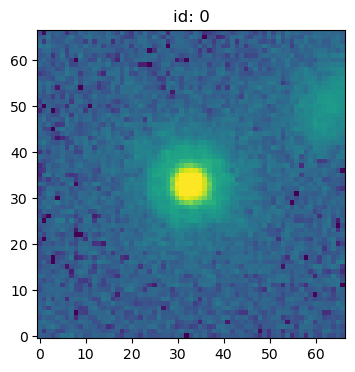

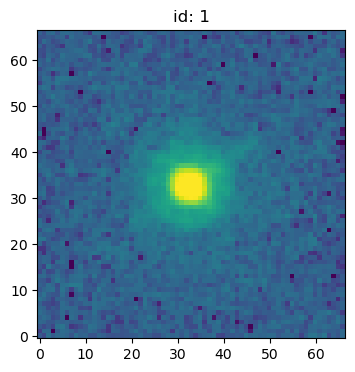

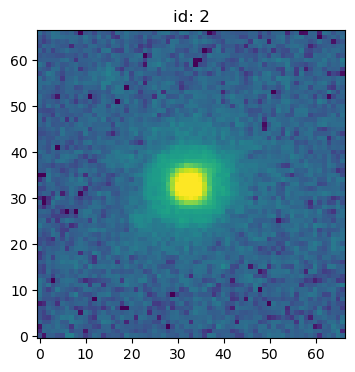

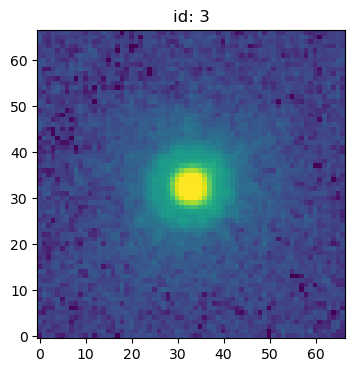

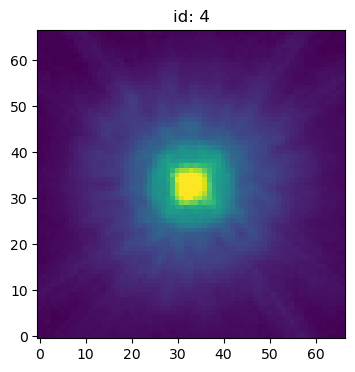

...

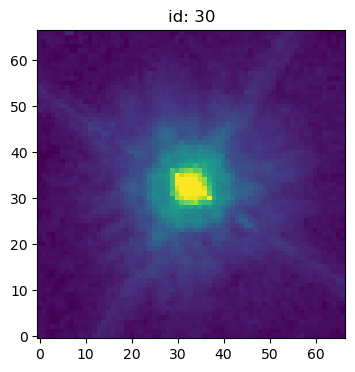

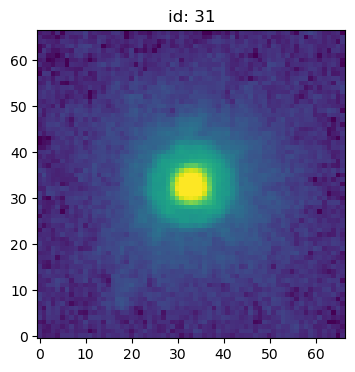

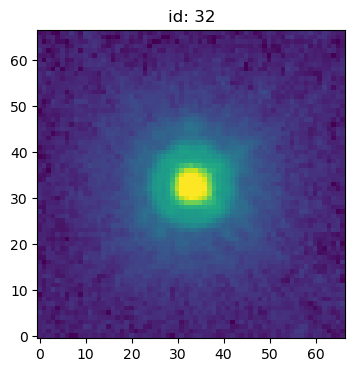

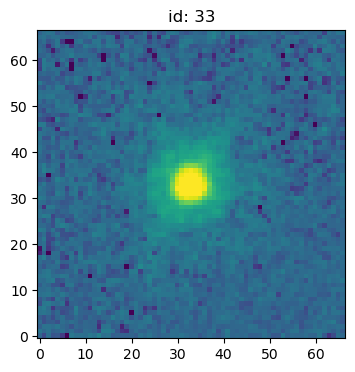

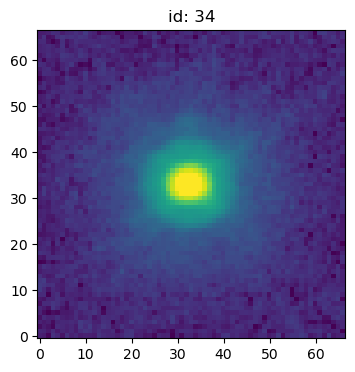

In [ ]:
idx_incld = np.asarray([5, 6, 8, 9, 11, 12, 20, 39, 42, 44, 
                        45, 47, 48, 115, 116, 117, 124, 125, 
                        126, 127, 128, 130, 132, 136, 137, 138, 
                       139, 140, 141, 142, 145, 175, 176, 177, 178])

mask = [False for i in range(len(peaks_tbl['x_peak']))]
for ii in range(len(idx_incld)):
    mask[int(idx_incld[ii])] = True
    
stars_tbl = Table()
stars_tbl['x'] = peaks_tbl['x_peak'][mask]  
stars_tbl['y'] = peaks_tbl['y_peak'][mask]

nddata = NDData(data=data_sci)
stars = extract_stars(nddata, stars_tbl, size=psf_size[int(id_fil)]) 

for ii in range(0,len(stars)):
    plt.figure(figsize=(4,4))
    plt.subplot()
    norm = simple_norm(stars[ii], 'log', percent=99.)
    plt.imshow(stars[ii], norm=norm, origin='lower', cmap='viridis')
    plt.title('id: %d' % ii)

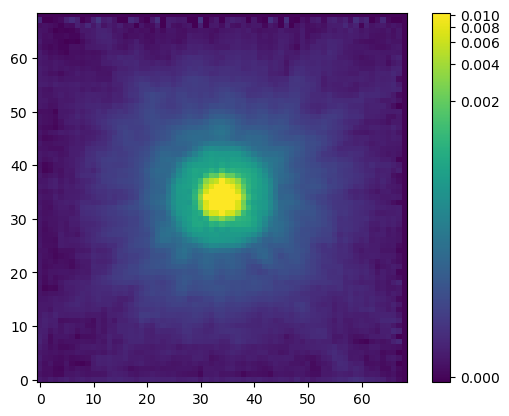

In [ ]:
epsf_builder = EPSFBuilder(oversampling=1, maxiters=3, progress_bar=False)  
epsf, fitted_stars = epsf_builder(stars) 

norm = simple_norm(epsf.data, 'log', percent=99.)
plt.imshow(epsf.data, norm=norm, origin='lower', cmap='viridis')
plt.colorbar()

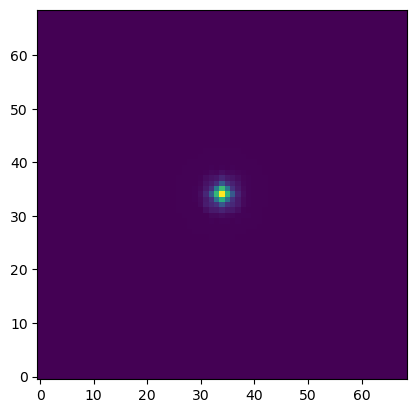

In [ ]:
name_out = 'PSF_%s.fits' % fil_names[int(id_fil)]
fits.writeto(name_out, epsf.data, overwrite=True)

hdu = fits.open(name_out)
plt.imshow(hdu[0].data, origin='lower')
hdu.close()

### (8) HST/F850LP

In [ ]:
id_fil = 7
print (filters[int(id_fil)])

hdu = fits.open(dir_images+sci_img[filters[int(id_fil)]])
data_sci = hdu[0].data
hdu.close()

hdu = fits.open(dir_images+wht_img[filters[int(id_fil)]])
data_err = 1.0/np.sqrt(hdu[0].data)
hdu.close()

peaks_tbl = find_peaks(data_sci, threshold=100.0, error=data_err) 
peaks_tbl['peak_value'].info.format = '%.8g'  # for consistent table output 
print(peaks_tbl)

print ('Number of stars: %d' % len(peaks_tbl['x_peak']))

hst_acs_f850lp
x_peak y_peak peak_value
------ ------ ----------
   676    101   1039.901
   955    504  200.14877
   461    987  364.77567
  1313   1576  307.70084
  1755   1642  474.24722
  1595   1873  142.70615
  1594   1879  361.68826
  1603   1880  328.08682
  1591   1882   302.1893
  1612   1883  257.84702
   ...    ...        ...
  7758   9113  153.41377
  7750   9117  115.32106
  7749   9121  110.08488
  7758   9121  5025.9019
  7760   9121  5018.0601
  7763   9121  4397.8726
  7756   9122  5056.2544
  7749   9125  115.19414
  7751   9129  105.11823
  5862   9210  602.39081
  6089   9910  204.95248
Length = 416 rows
Number of stars: 416


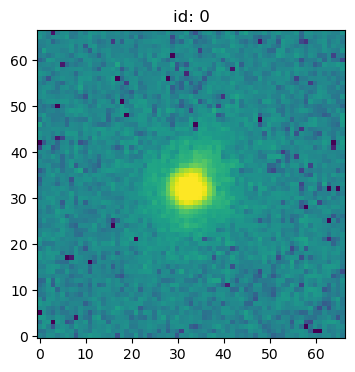

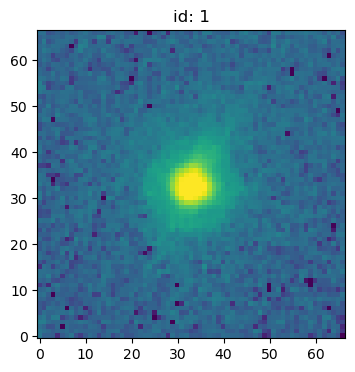

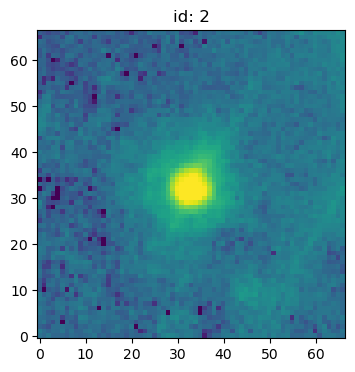

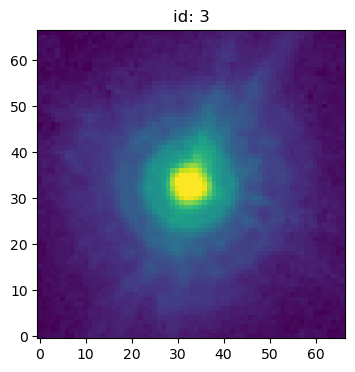

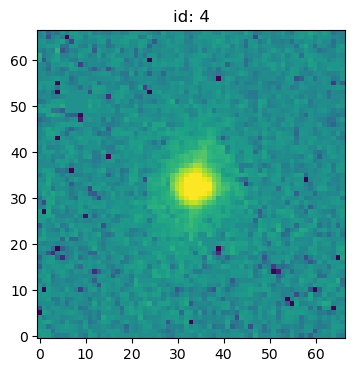

...

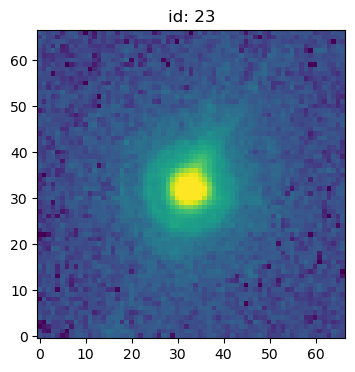

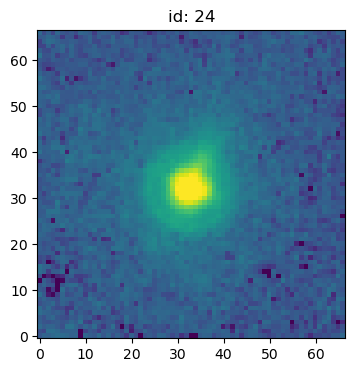

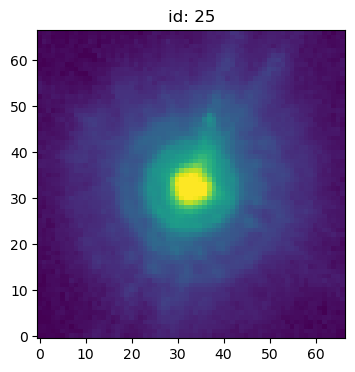

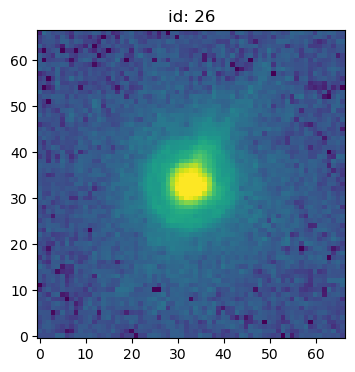

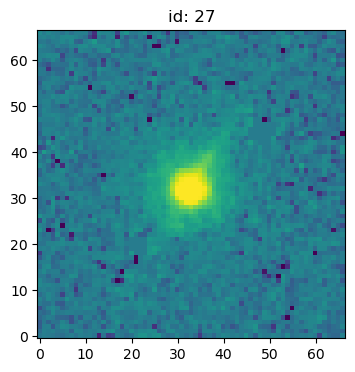

In [ ]:
idx_incld = np.asarray([211, 212, 213, 215, 216, 241, 287, 288, 
                       291, 292, 293, 294, 295, 299, 376, 389, 
                        390, 391, 392, 394, 396, 397, 398, 399,
                        401, 404, 414, 415])

mask = [False for i in range(len(peaks_tbl['x_peak']))]
for ii in range(len(idx_incld)):
    mask[int(idx_incld[ii])] = True
    
stars_tbl = Table()
stars_tbl['x'] = peaks_tbl['x_peak'][mask]  
stars_tbl['y'] = peaks_tbl['y_peak'][mask]

nddata = NDData(data=data_sci)
stars = extract_stars(nddata, stars_tbl, size=psf_size[int(id_fil)]) 

for ii in range(0,len(stars)):
    plt.figure(figsize=(4,4))
    plt.subplot()
    norm = simple_norm(stars[ii], 'log', percent=99.)
    plt.imshow(stars[ii], norm=norm, origin='lower', cmap='viridis')
    plt.title('id: %d' % ii)

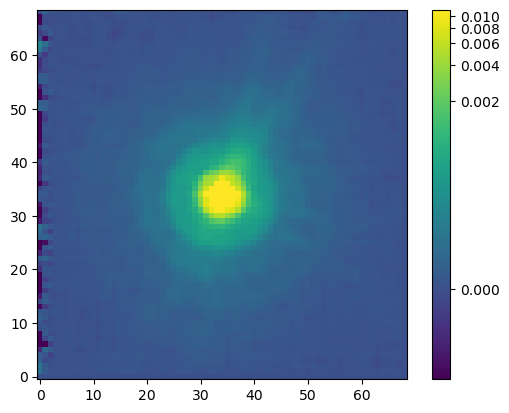

In [ ]:
epsf_builder = EPSFBuilder(oversampling=1, maxiters=3, progress_bar=False)  
epsf, fitted_stars = epsf_builder(stars) 

norm = simple_norm(epsf.data, 'log', percent=99.)
plt.imshow(epsf.data, norm=norm, origin='lower', cmap='viridis')
plt.colorbar()

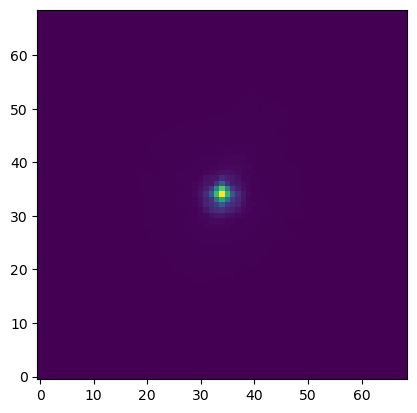

In [ ]:
name_out = 'PSF_%s.fits' % fil_names[int(id_fil)]
fits.writeto(name_out, epsf.data, overwrite=True)

hdu = fits.open(name_out)
plt.imshow(hdu[0].data, origin='lower')
hdu.close()

### (9) JWST/F115W

In [ ]:
id_fil = 8
print (filters[int(id_fil)])

hdu = fits.open(dir_images+sci_img[filters[int(id_fil)]])
data_sci = hdu[0].data
hdu.close()

hdu = fits.open(dir_images+wht_img[filters[int(id_fil)]])
data_err = 1.0/np.sqrt(hdu[0].data)
hdu.close()

peaks_tbl = find_peaks(data_sci, threshold=200.0, error=data_err) 
peaks_tbl['peak_value'].info.format = '%.8g'  # for consistent table output 
print(peaks_tbl)

print ('Number of stars: %d' % len(peaks_tbl['x_peak']))

jwst_nircam_f115w
x_peak y_peak peak_value
------ ------ ----------
 15545   2681  320.33038
 18751   3604  308.17017
 16660   5417  204.30246
 16663   5427  209.79573
 16664   5429  213.42313
 16668   5442  208.89969
 16669   5444  257.59793
 16670   5446  243.25212
 16671   5450  334.48917
 16673   5454  266.01682
   ...    ...        ...
 17961   9156  552.19098
 17967   9157  238.94504
 13138  10944   218.2963
 13171  10951  205.37274
 13134  10972  223.69974
 13134  10973  223.69974
 13170  10979  228.84291
 13160  10987  224.95351
 13138  10989  203.35625
 13127  10993  226.33835
 11979  16478  211.16092
Length = 1681 rows
Number of stars: 1681


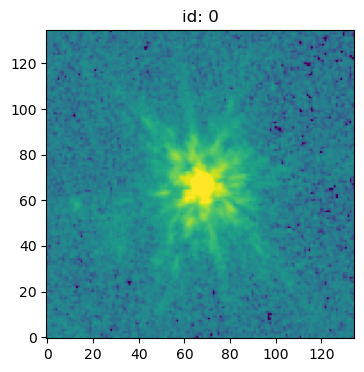

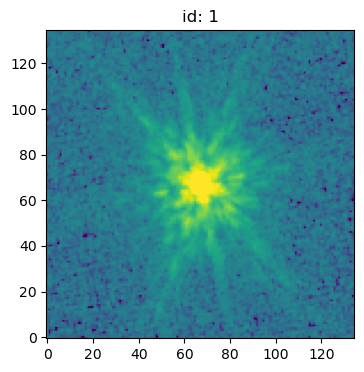

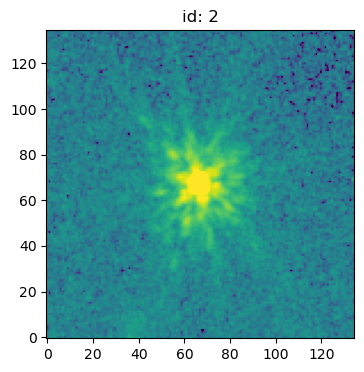

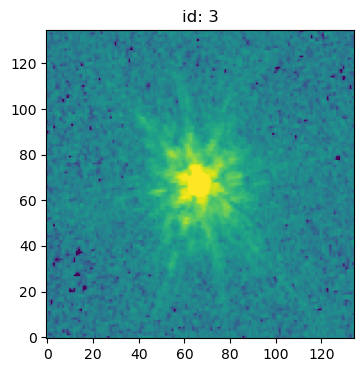

In [ ]:
idx_incld = np.asarray([0, 1, 131, 1680])

mask = [False for i in range(len(peaks_tbl['x_peak']))]
for ii in range(len(idx_incld)):
    mask[int(idx_incld[ii])] = True
    
stars_tbl = Table()
stars_tbl['x'] = peaks_tbl['x_peak'][mask]  
stars_tbl['y'] = peaks_tbl['y_peak'][mask]

nddata = NDData(data=data_sci)
stars = extract_stars(nddata, stars_tbl, size=psf_size[int(id_fil)]) 

for ii in range(0,len(stars)):
    plt.figure(figsize=(4,4))
    plt.subplot()
    norm = simple_norm(stars[ii], 'log', percent=99.)
    plt.imshow(stars[ii], norm=norm, origin='lower', cmap='viridis')
    plt.title('id: %d' % ii)

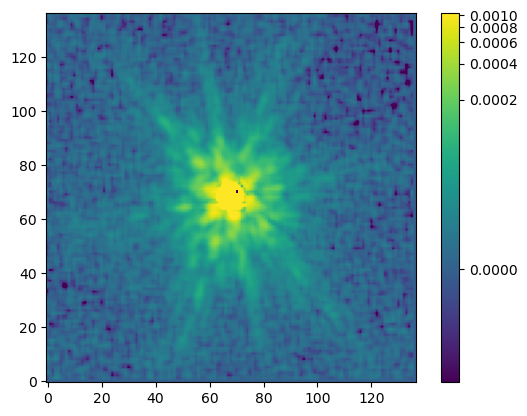

In [ ]:
epsf_builder = EPSFBuilder(oversampling=1, maxiters=3, progress_bar=False)  
epsf, fitted_stars = epsf_builder(stars) 

norm = simple_norm(epsf.data, 'log', percent=99.)
plt.imshow(epsf.data, norm=norm, origin='lower', cmap='viridis')
plt.colorbar()

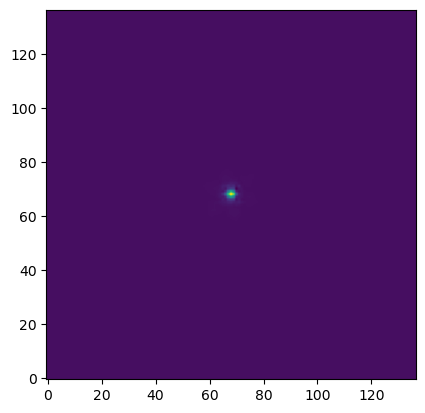

In [ ]:
name_out = 'PSF_%s.fits' % fil_names[int(id_fil)]
fits.writeto(name_out, epsf.data, overwrite=True)

hdu = fits.open(name_out)
plt.imshow(hdu[0].data, origin='lower')
hdu.close()

### (10) JWST/F150W

In [ ]:
id_fil = 9
print (filters[int(id_fil)])

hdu = fits.open(dir_images+sci_img[filters[int(id_fil)]])
data_sci = hdu[0].data
hdu.close()

hdu = fits.open(dir_images+wht_img[filters[int(id_fil)]])
data_err = 1.0/np.sqrt(hdu[0].data)
hdu.close()

peaks_tbl = find_peaks(data_sci, threshold=150.0, error=data_err) 
peaks_tbl['peak_value'].info.format = '%.8g'  # for consistent table output 
print(peaks_tbl)

print ('Number of stars: %d' % len(peaks_tbl['x_peak']))

jwst_nircam_f150w
x_peak y_peak peak_value
------ ------ ----------
 13013   1453  154.37469
 12574   2563  186.91008
 15872   5871  196.66896
 15049   7368  200.89888
 15052   7368  216.87276
 15052   7369  216.87276
 15044   7370  178.57034
 15058   7373  177.48853
 15059   7373  177.48853
 15059   7376  193.17101
   ...    ...        ...
 13131  10965  187.40645
 13131  10966  187.40645
 13172  10975   162.2309
 13161  10993  168.46838
 16372  11328  155.93893
 12818  13474  154.43408
 12819  13474  154.43408
 12818  13475  154.43408
 12819  13475  154.43408
 12816  13487  151.21095
 11978  16478  210.75044
Length = 552 rows
Number of stars: 552


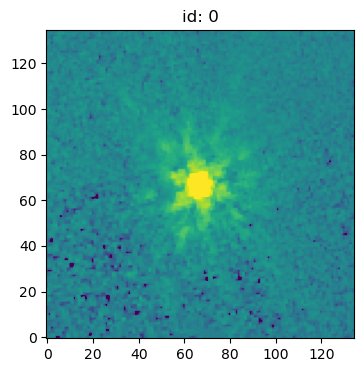

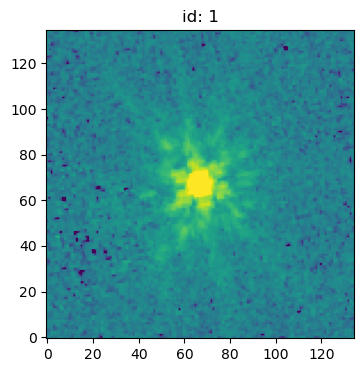

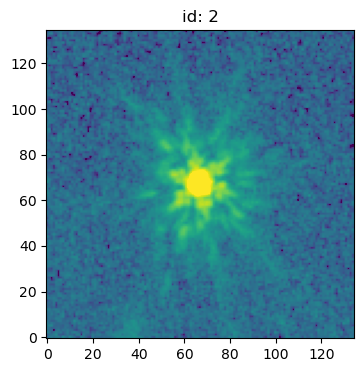

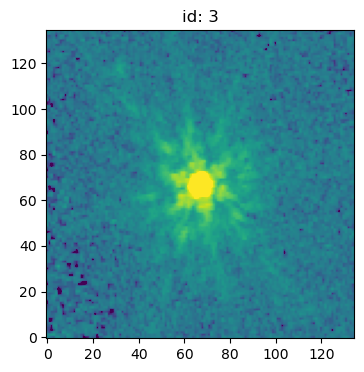

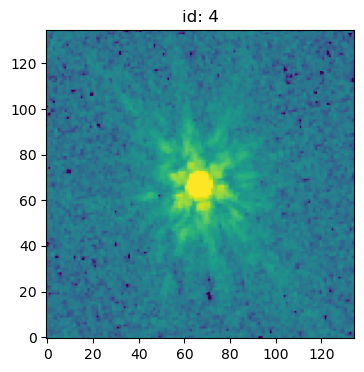

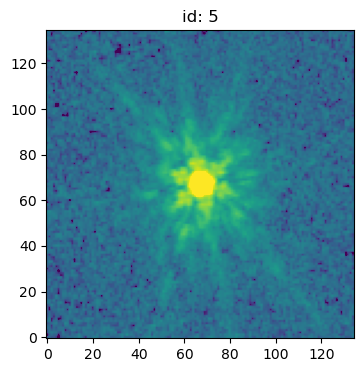

In [ ]:
idx_incld = np.asarray([0, 1, 2, 530, 545, 551])

mask = [False for i in range(len(peaks_tbl['x_peak']))]
for ii in range(len(idx_incld)):
    mask[int(idx_incld[ii])] = True
    
stars_tbl = Table()
stars_tbl['x'] = peaks_tbl['x_peak'][mask]  
stars_tbl['y'] = peaks_tbl['y_peak'][mask]

nddata = NDData(data=data_sci)
stars = extract_stars(nddata, stars_tbl, size=psf_size[int(id_fil)]) 

for ii in range(0,len(stars)):
    plt.figure(figsize=(4,4))
    plt.subplot()
    norm = simple_norm(stars[ii], 'log', percent=99.)
    plt.imshow(stars[ii], norm=norm, origin='lower', cmap='viridis')
    plt.title('id: %d' % ii)

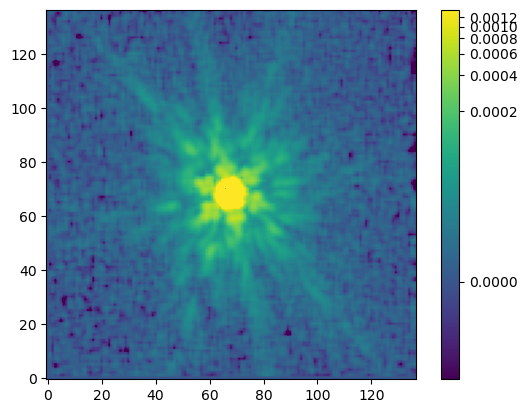

In [ ]:
epsf_builder = EPSFBuilder(oversampling=1, maxiters=3, progress_bar=False)  
epsf, fitted_stars = epsf_builder(stars) 

norm = simple_norm(epsf.data, 'log', percent=99.)
plt.imshow(epsf.data, norm=norm, origin='lower', cmap='viridis')
plt.colorbar()

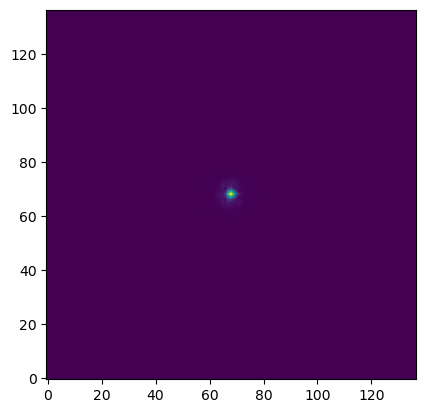

In [ ]:
name_out = 'PSF_%s.fits' % fil_names[int(id_fil)]
fits.writeto(name_out, epsf.data, overwrite=True)

hdu = fits.open(name_out)
plt.imshow(hdu[0].data, origin='lower')
hdu.close()

### (11) JWST/F200W

In [ ]:
id_fil = 10
print (filters[int(id_fil)])

hdu = fits.open(dir_images+sci_img[filters[int(id_fil)]])
data_sci = hdu[0].data
hdu.close()

hdu = fits.open(dir_images+wht_img[filters[int(id_fil)]])
data_err = 1.0/np.sqrt(hdu[0].data)
hdu.close()

peaks_tbl = find_peaks(data_sci, threshold=100.0, error=data_err) 
peaks_tbl['peak_value'].info.format = '%.8g'  # for consistent table output 
print(peaks_tbl)

print ('Number of stars: %d' % len(peaks_tbl['x_peak']))

jwst_nircam_f200w
x_peak y_peak peak_value
------ ------ ----------
 14221   2275  196.11137
 15546   2681   157.4928
 17187   4149  106.30064
 17179   4152  125.76031
 17185   4158  168.54892
 18765   4344  105.40903
 12364   5865  112.09367
 12368   5865  109.73777
 12353   5870  132.55246
 15872   5871  125.30528
   ...    ...        ...
 12795  13482  127.06888
 12816  13486  118.61229
 12800  13487  100.93311
 12803  13489  144.59464
 15580  15885  111.23064
  8483  16245  176.95934
 11979  16478   124.9151
  5336  16589  155.90556
 11043  16776  114.22701
  7451  17054  144.19891
  8254  17387  123.56432
Length = 564 rows
Number of stars: 564


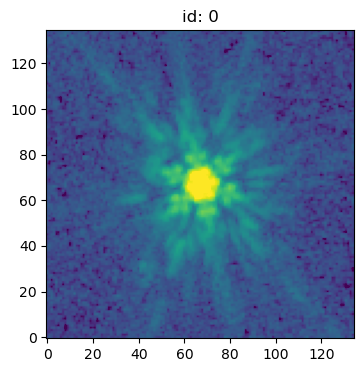

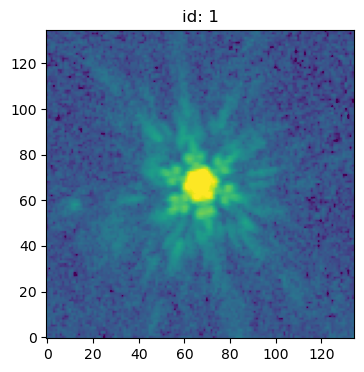

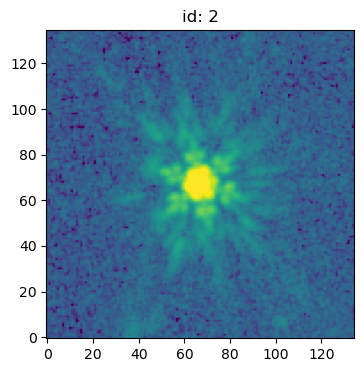

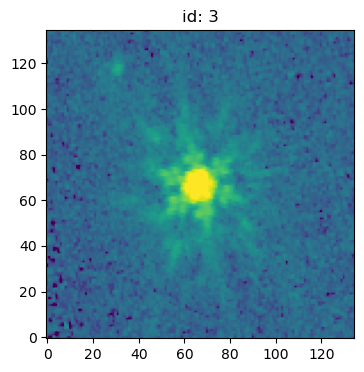

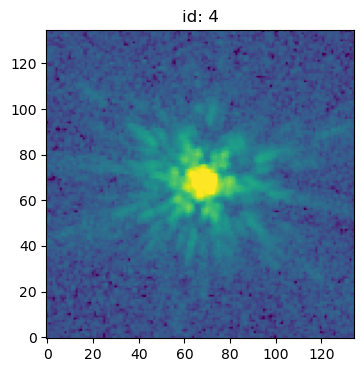

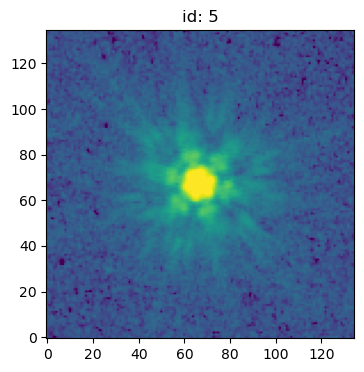

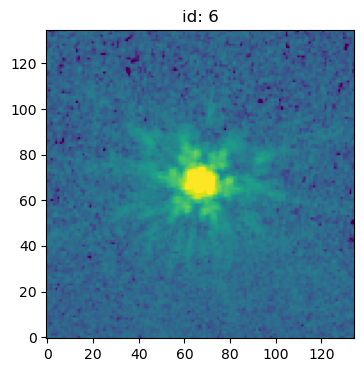

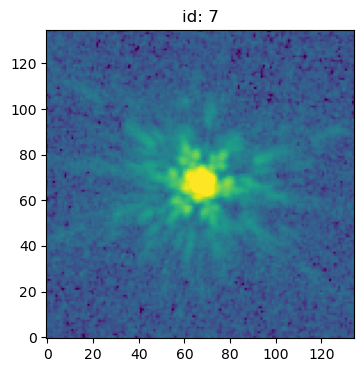

In [ ]:
idx_incld = np.asarray([0, 1, 9, 512, 558, 559, 561, 562])

mask = [False for i in range(len(peaks_tbl['x_peak']))]
for ii in range(len(idx_incld)):
    mask[int(idx_incld[ii])] = True
    
stars_tbl = Table()
stars_tbl['x'] = peaks_tbl['x_peak'][mask]  
stars_tbl['y'] = peaks_tbl['y_peak'][mask]

nddata = NDData(data=data_sci)
stars = extract_stars(nddata, stars_tbl, size=psf_size[int(id_fil)]) 

for ii in range(0,len(stars)):
    plt.figure(figsize=(4,4))
    plt.subplot()
    norm = simple_norm(stars[ii], 'log', percent=99.)
    plt.imshow(stars[ii], norm=norm, origin='lower', cmap='viridis')
    plt.title('id: %d' % ii)

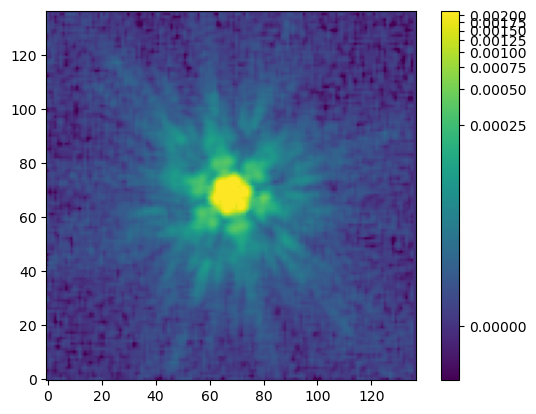

In [ ]:
epsf_builder = EPSFBuilder(oversampling=1, maxiters=3, progress_bar=False)  
epsf, fitted_stars = epsf_builder(stars) 

norm = simple_norm(epsf.data, 'log', percent=99.)
plt.imshow(epsf.data, norm=norm, origin='lower', cmap='viridis')
plt.colorbar()

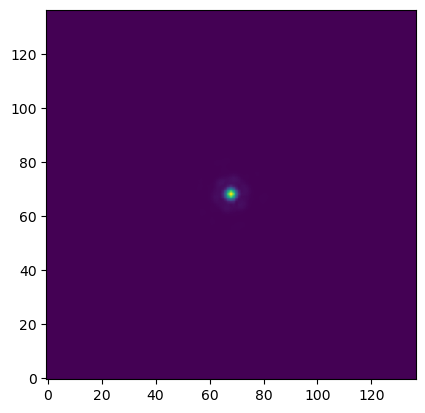

In [ ]:
name_out = 'PSF_%s.fits' % fil_names[int(id_fil)]
fits.writeto(name_out, epsf.data, overwrite=True)

hdu = fits.open(name_out)
plt.imshow(hdu[0].data, origin='lower')
hdu.close()

### (12) JWST/F277W

In [ ]:
id_fil = 11
print (filters[int(id_fil)])

hdu = fits.open(dir_images+sci_img[filters[int(id_fil)]])
data_sci = hdu[0].data
hdu.close()

hdu = fits.open(dir_images+wht_img[filters[int(id_fil)]])
data_err = 1.0/np.sqrt(hdu[0].data)
hdu.close()

peaks_tbl = find_peaks(data_sci, threshold=100.0, error=data_err) 
peaks_tbl['peak_value'].info.format = '%.8g'  # for consistent table output 
print(peaks_tbl)

print ('Number of stars: %d' % len(peaks_tbl['x_peak']))

jwst_nircam_f277w
x_peak y_peak peak_value
------ ------ ----------
  6507    726  102.17884
  7773   1340  144.74513
  9059   1738   114.8181
  7936   2935  107.83755
  6189   2937  101.48147
  6190   2937  101.48147
  6269   3325    103.216
  7533   3686  100.93311
  7533   3687  100.93311
  7534   3687  100.93311
   ...    ...        ...
  6401   6747  108.19808
  6709   6808  112.32606
  7148   7070  127.48968
  6666   7081  104.21953
  8366   7581   174.4016
  6821   7652  102.78084
  6870   7702  107.46315
  7790   7942  103.80982
  8131   8105  103.25086
  5863   8181  144.60516
  5989   8239  118.21328
Length = 133 rows
Number of stars: 133


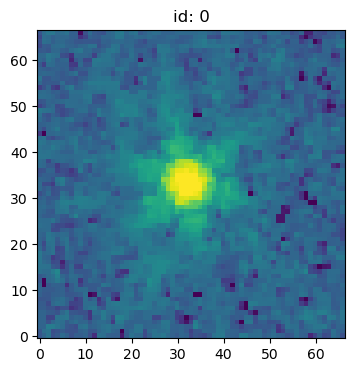

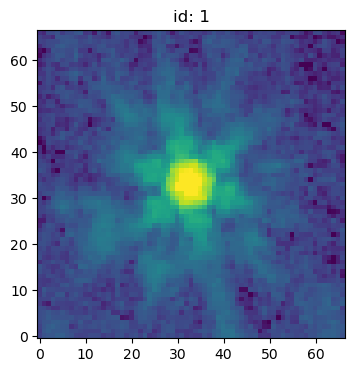

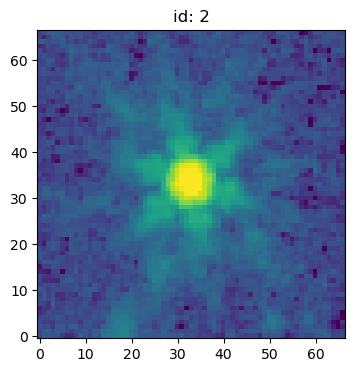

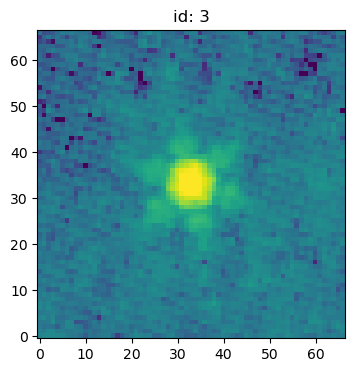

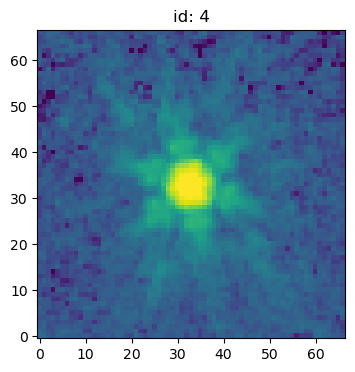

In [ ]:
idx_incld = np.asarray([0, 1, 3, 11, 132])

mask = [False for i in range(len(peaks_tbl['x_peak']))]
for ii in range(len(idx_incld)):
    mask[int(idx_incld[ii])] = True
    
stars_tbl = Table()
stars_tbl['x'] = peaks_tbl['x_peak'][mask]  
stars_tbl['y'] = peaks_tbl['y_peak'][mask]

nddata = NDData(data=data_sci)
stars = extract_stars(nddata, stars_tbl, size=psf_size[int(id_fil)]) 

for ii in range(0,len(stars)):
    plt.figure(figsize=(4,4))
    plt.subplot()
    norm = simple_norm(stars[ii], 'log', percent=99.)
    plt.imshow(stars[ii], norm=norm, origin='lower', cmap='viridis')
    plt.title('id: %d' % ii)

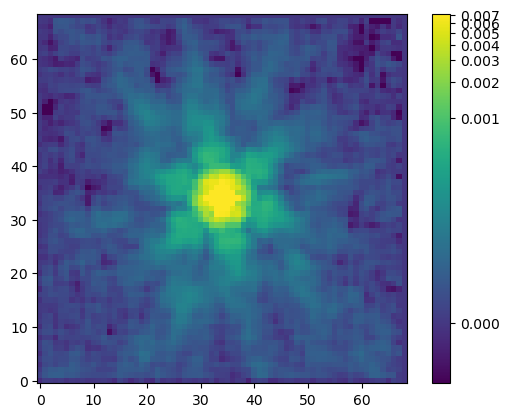

In [ ]:
epsf_builder = EPSFBuilder(oversampling=1, maxiters=3, progress_bar=False)  
epsf, fitted_stars = epsf_builder(stars) 

norm = simple_norm(epsf.data, 'log', percent=99.)
plt.imshow(epsf.data, norm=norm, origin='lower', cmap='viridis')
plt.colorbar()

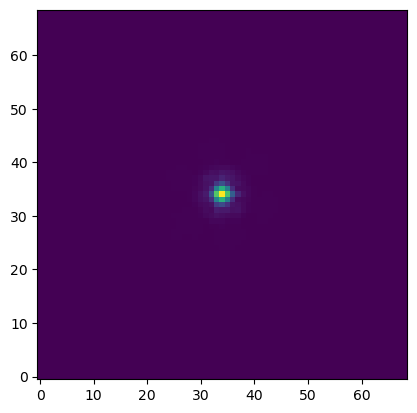

In [ ]:
name_out = 'PSF_%s.fits' % fil_names[int(id_fil)]
fits.writeto(name_out, epsf.data, overwrite=True)

hdu = fits.open(name_out)
plt.imshow(hdu[0].data, origin='lower')
hdu.close()

### (13) JWST/F356W

In [ ]:
id_fil = 12
print (filters[int(id_fil)])

hdu = fits.open(dir_images+sci_img[filters[int(id_fil)]])
data_sci = hdu[0].data
hdu.close()

hdu = fits.open(dir_images+wht_img[filters[int(id_fil)]])
data_err = 1.0/np.sqrt(hdu[0].data)
hdu.close()

peaks_tbl = find_peaks(data_sci, threshold=120.0, error=data_err) 
peaks_tbl['peak_value'].info.format = '%.8g'  # for consistent table output 
print(peaks_tbl)

print ('Number of stars: %d' % len(peaks_tbl['x_peak']))

jwst_nircam_f356w
x_peak y_peak peak_value
------ ------ ----------
  9375   1801  120.03334
  8446   3340  157.51544
  8139   3404  136.74088
  5751   3859   137.6059
  5753   3860  137.62642
  5756   3862  137.53484
  5766   3862  137.61859
  5763   3863  137.58234
  5773   3863  137.60866
  5769   3864  137.58827
   ...    ...        ...
  8814   4471  183.38966
  8802   4472  121.17011
  8824   4472  175.77586
  8805   4473  127.27802
  8820   4473  180.37225
  8831   4473  178.78372
  8831   4474  178.78372
  5780   4991  168.72017
  6570   5500  129.77861
  8139   6194  146.11314
  5750   8299  148.27373
Length = 678 rows
Number of stars: 678


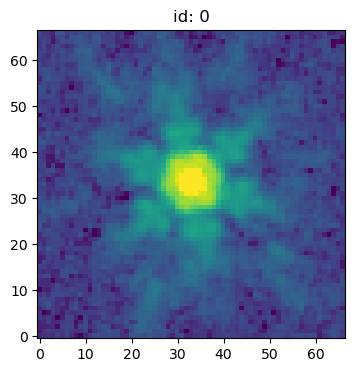

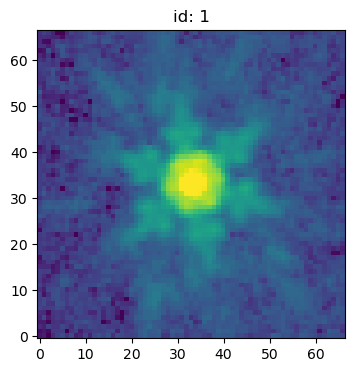

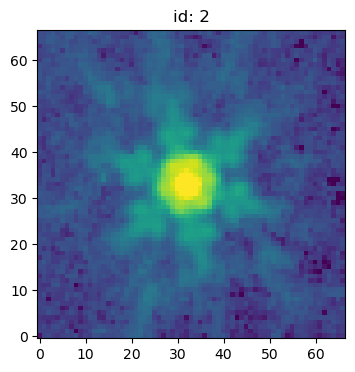

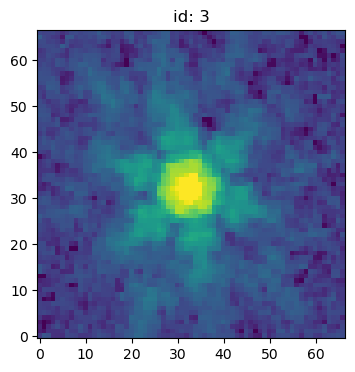

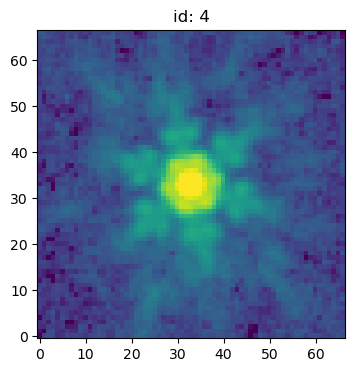

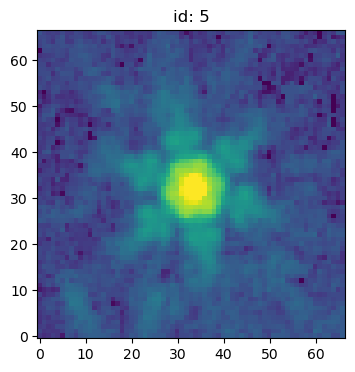

In [ ]:
idx_incld = np.asarray([0, 1, 2, 674, 676, 677])

mask = [False for i in range(len(peaks_tbl['x_peak']))]
for ii in range(len(idx_incld)):
    mask[int(idx_incld[ii])] = True
    
stars_tbl = Table()
stars_tbl['x'] = peaks_tbl['x_peak'][mask]  
stars_tbl['y'] = peaks_tbl['y_peak'][mask]

nddata = NDData(data=data_sci)
stars = extract_stars(nddata, stars_tbl, size=psf_size[int(id_fil)]) 

for ii in range(0,len(stars)):
    plt.figure(figsize=(4,4))
    plt.subplot()
    norm = simple_norm(stars[ii], 'log', percent=99.)
    plt.imshow(stars[ii], norm=norm, origin='lower', cmap='viridis')
    plt.title('id: %d' % ii)

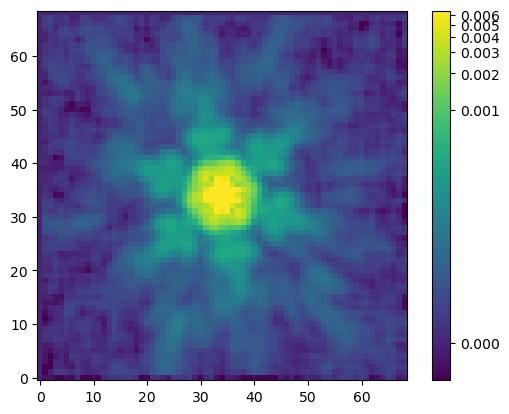

In [ ]:
epsf_builder = EPSFBuilder(oversampling=1, maxiters=3, progress_bar=False)  
epsf, fitted_stars = epsf_builder(stars) 

norm = simple_norm(epsf.data, 'log', percent=99.)
plt.imshow(epsf.data, norm=norm, origin='lower', cmap='viridis')
plt.colorbar()

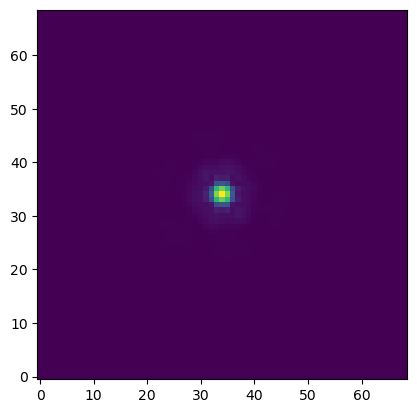

In [ ]:
name_out = 'PSF_%s.fits' % fil_names[int(id_fil)]
fits.writeto(name_out, epsf.data, overwrite=True)

hdu = fits.open(name_out)
plt.imshow(hdu[0].data, origin='lower')
hdu.close()

### (14) JWST/F444W

In [ ]:
id_fil = 13
print (filters[int(id_fil)])

hdu = fits.open(dir_images+sci_img[filters[int(id_fil)]])
data_sci = hdu[0].data
hdu.close()

hdu = fits.open(dir_images+wht_img[filters[int(id_fil)]])
data_err = 1.0/np.sqrt(hdu[0].data)
hdu.close()

peaks_tbl = find_peaks(data_sci, threshold=80.0, error=data_err) 
peaks_tbl['peak_value'].info.format = '%.8g'  # for consistent table output 
print(peaks_tbl)

print ('Number of stars: %d' % len(peaks_tbl['x_peak']))

jwst_nircam_f444w
x_peak y_peak peak_value
------ ------ ----------
  7988   1334  100.65073
  6269   3325  105.88028
  8447   3340  88.039467
  8138   3404   88.73465
  9011   3486  85.591743
  9016   3486  96.734467
  9016   3487  96.734467
  8908   4374  81.699974
  8910   4379  100.03454
  8914   4385  83.771027
   ...    ...        ...
  6571   5502  85.224998
  6796   5590  151.76241
  6253   5656  136.38606
  7327   6089  90.692215
  7328   6089  90.692215
  6251   6341  95.993355
  8130   6662  141.53204
  5153   7591  119.70832
  6870   7702  82.894501
  5279   7967   105.7961
  5751   8298  89.810448
Length = 43 rows
Number of stars: 43


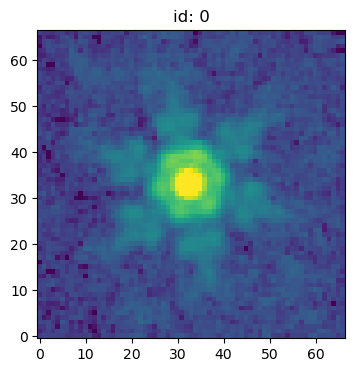

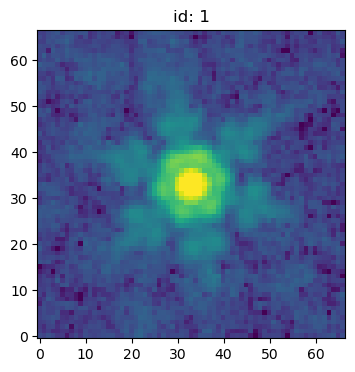

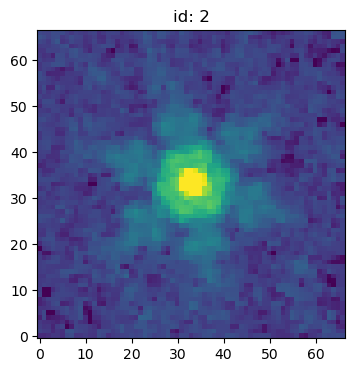

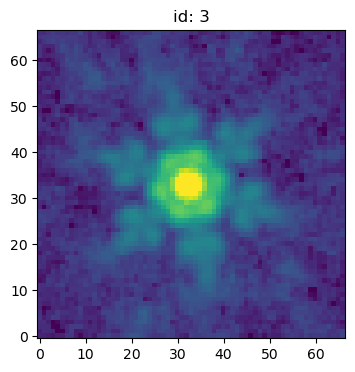

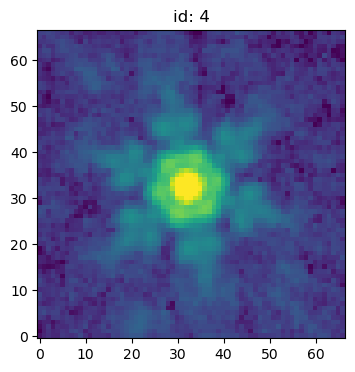

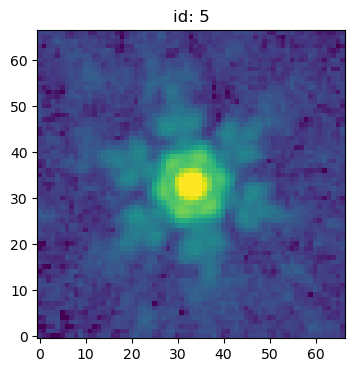

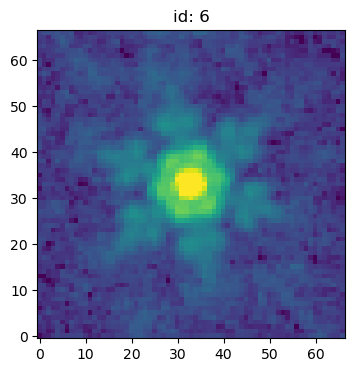

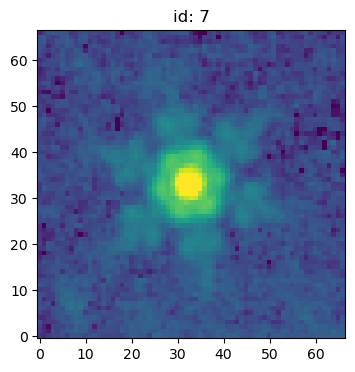

In [ ]:
idx_incld = np.asarray([2, 3, 23, 33, 38, 39, 41, 42])

mask = [False for i in range(len(peaks_tbl['x_peak']))]
for ii in range(len(idx_incld)):
    mask[int(idx_incld[ii])] = True
    
stars_tbl = Table()
stars_tbl['x'] = peaks_tbl['x_peak'][mask]  
stars_tbl['y'] = peaks_tbl['y_peak'][mask]

nddata = NDData(data=data_sci)
stars = extract_stars(nddata, stars_tbl, size=psf_size[int(id_fil)]) 

for ii in range(0,len(stars)):
    plt.figure(figsize=(4,4))
    plt.subplot()
    norm = simple_norm(stars[ii], 'log', percent=99.)
    plt.imshow(stars[ii], norm=norm, origin='lower', cmap='viridis')
    plt.title('id: %d' % ii)

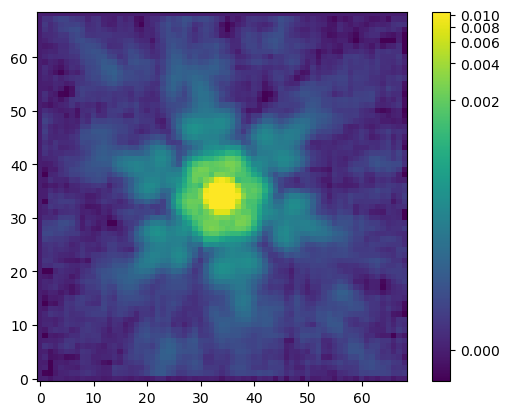

In [ ]:
epsf_builder = EPSFBuilder(oversampling=1, maxiters=3, progress_bar=False)  
epsf, fitted_stars = epsf_builder(stars) 

norm = simple_norm(epsf.data, 'log', percent=99.)
plt.imshow(epsf.data, norm=norm, origin='lower', cmap='viridis')
plt.colorbar()

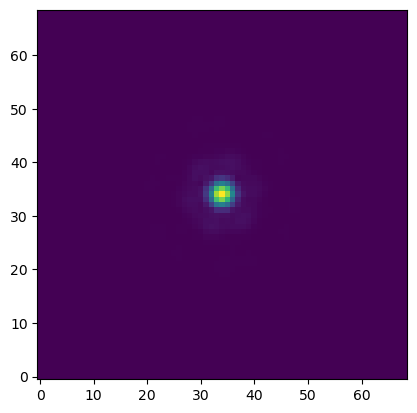

In [ ]:
name_out = 'PSF_%s.fits' % fil_names[int(id_fil)]
fits.writeto(name_out, epsf.data, overwrite=True)

hdu = fits.open(name_out)
plt.imshow(hdu[0].data, origin='lower')
hdu.close()

### (15) JWST/F480M

In [ ]:
id_fil = 14
print (filters[int(id_fil)])

hdu = fits.open(dir_images+sci_img[filters[int(id_fil)]])
data_sci = hdu[0].data
hdu.close()

hdu = fits.open(dir_images+wht_img[filters[int(id_fil)]])
data_err = 1.0/np.sqrt(hdu[0].data)
hdu.close()

peaks_tbl = find_peaks(data_sci, threshold=80.0, error=data_err) 
peaks_tbl['peak_value'].info.format = '%.8g'  # for consistent table output 
print(peaks_tbl)

print ('Number of stars: %d' % len(peaks_tbl['x_peak']))

jwst_nircam_f480m
x_peak y_peak peak_value
------ ------ ----------
  5935   5434  149.76509
  6583   5465  135.16153
  6578   5467  167.13902
  6563   5468  144.05466
  6568   5469  193.57837
  6583   5470  156.87851
  6563   5473  168.34746
  6573   5473  81.656479
  6574   5473  81.656479
  6579   5473  151.62872
   ...    ...        ...
  6408   6734  161.05615
  6397   6736  173.50462
  6409   6741  168.23096
  6398   6743  170.00662
  6404   6746  133.29118
  7236   6775  320.98141
  2650   6878   357.3707
  3810   8007   131.3918
  5976   8399  95.088745
  4449   8482  148.11137
  4126   8693  140.77995
Length = 50 rows
Number of stars: 50


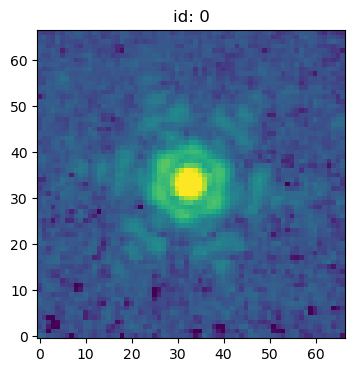

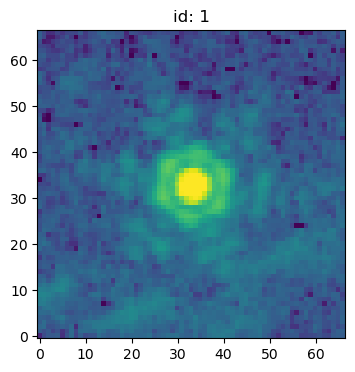

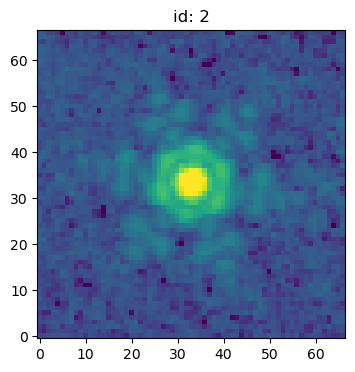

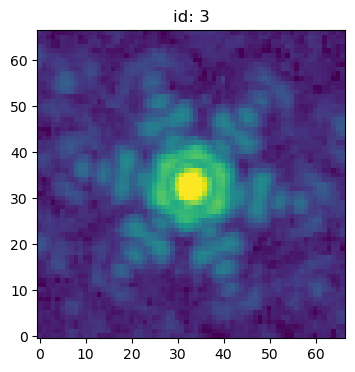

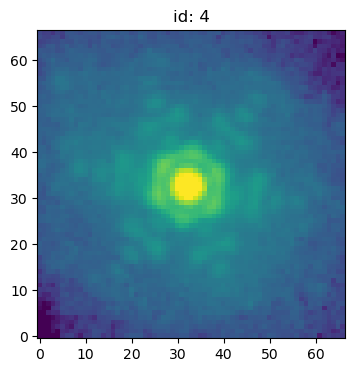

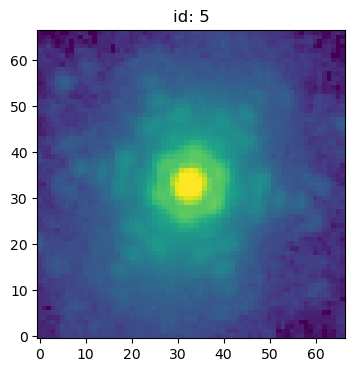

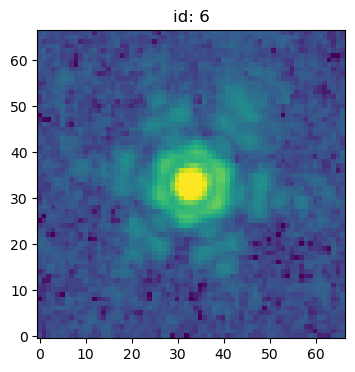

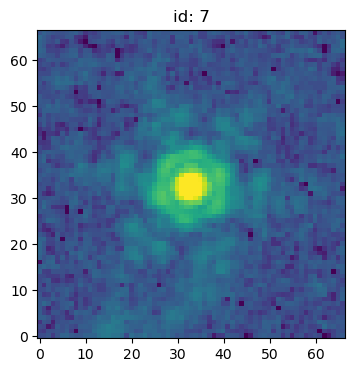

In [ ]:
idx_incld = np.asarray([0, 30, 36, 37, 44, 45, 46, 47])

mask = [False for i in range(len(peaks_tbl['x_peak']))]
for ii in range(len(idx_incld)):
    mask[int(idx_incld[ii])] = True
    
stars_tbl = Table()
stars_tbl['x'] = peaks_tbl['x_peak'][mask]  
stars_tbl['y'] = peaks_tbl['y_peak'][mask]

nddata = NDData(data=data_sci)
stars = extract_stars(nddata, stars_tbl, size=psf_size[int(id_fil)]) 

for ii in range(0,len(stars)):
    plt.figure(figsize=(4,4))
    plt.subplot()
    norm = simple_norm(stars[ii], 'log', percent=99.)
    plt.imshow(stars[ii], norm=norm, origin='lower', cmap='viridis')
    plt.title('id: %d' % ii)

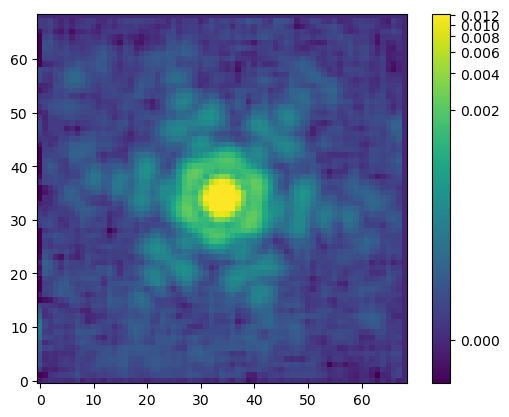

In [ ]:
epsf_builder = EPSFBuilder(oversampling=1, maxiters=3, progress_bar=False)  
epsf, fitted_stars = epsf_builder(stars) 

norm = simple_norm(epsf.data, 'log', percent=99.)
plt.imshow(epsf.data, norm=norm, origin='lower', cmap='viridis')
plt.colorbar()

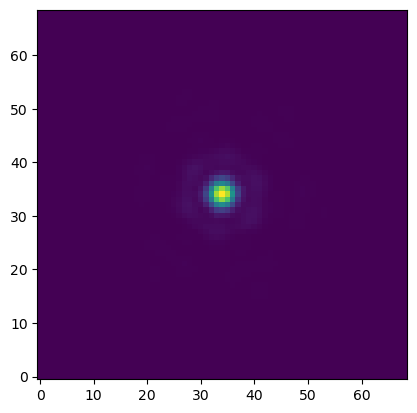

In [ ]:
name_out = 'PSF_%s.fits' % fil_names[int(id_fil)]
fits.writeto(name_out, epsf.data, overwrite=True)

hdu = fits.open(name_out)
plt.imshow(hdu[0].data, origin='lower')
hdu.close()